# Stock Market Analysis And Forecasting 
A stock market, equity market, or share market is the aggregation of buyers and sellers of stocks (also called shares), which represent ownership claims on businesses; these may include securities listed on a public stock exchange, as well as stock that is only traded privately, such as shares of private companies which are sold to investors through equity crowdfunding platforms. Investment in the stock market is most often done via stockbrokerages and electronic trading platforms. Investment is usually made with an investment strategy in mind.

The task of stock prediction has always been a challenging
problem for statistics experts and finance. The main reason
behind this prediction is buying stocks that are likely to
increase in price and then selling stocks that are probably
to fall. Generally, there are two ways for stock market prediction.
Fundamental analysis is one of them and relies on a
company's technique and fundamental information like market position, expenses and annual growth rates. The second
one is the technical analysis method, which concentrates on
previous stock prices and values.

In the first part of our project, we will try to analyze the data. and in the second part, we will forecast the stock market.

### Dataset
 1. Google
 2. Microsoft
 3. IBM
 4. Amazon

### Analysis

We will find the distribution of close and open. Then we will find the correlation between close and open. After that, we will visualize the attributes[Open, High, Low, Close, volume] of our datasets. Then we compare the "High" and "Close" of each datasets. At last, we will find the trend and seasonality in the dataset.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from pylab import rcParams
import statsmodels.api as sm
from sklearn.preprocessing import MinMaxScaler
import torch
import torch.nn as nn
import math, time
from sklearn.metrics import mean_squared_error

In [2]:
google = pd.read_csv('GOOGL_2006-01-01_to_2018-01-01.csv', index_col='Date', parse_dates=['Date'])
google.head()

,Open,High,Low,Close,Volume,Name
Date,,,,,,
2006-01-03,211.47,218.05,209.32,217.83,13137450,GOOGL
2006-01-04,222.17,224.70,220.09,222.84,15292353,GOOGL
2006-01-05,223.22,226.00,220.97,225.85,10815661,GOOGL
2006-01-06,228.66,235.49,226.85,233.06,17759521,GOOGL
2006-01-09,233.44,236.94,230.70,233.68,12795837,GOOGL


In [3]:
google.describe()

,Open,High,Low,Close,Volume
count,3019.000000,3019.000000,3019.000000,3019.000000,3.019000e+03
mean,428.200802,431.835618,424.130275,428.044001,3.551504e+06
std,236.320026,237.514087,234.923747,236.343238,3.038599e+06
min,131.390000,134.820000,123.770000,128.850000,5.211410e+05
25%,247.775000,250.190000,244.035000,247.605000,1.760854e+06
50%,310.480000,312.810000,307.790000,310.080000,2.517630e+06
75%,572.140000,575.975000,565.900000,570.770000,4.242182e+06
max,1083.020000,1086.490000,1072.270000,1085.090000,4.118289e+07


After describing the google dataset, there is a high difference between the minimum and maximum values. And 75% of the value is close to the mean.

In [4]:
google.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3019 entries, 2006-01-03 to 2017-12-29
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Open    3019 non-null   float64
 1   High    3019 non-null   float64
 2   Low     3019 non-null   float64
 3   Close   3019 non-null   float64
 4   Volume  3019 non-null   int64  
 5   Name    3019 non-null   object 
dtypes: float64(4), int64(1), object(1)
memory usage: 165.1+ KB


In [5]:
google.isna().sum()

Open      0
High      0
Low       0
Close     0
Volume    0
Name      0
dtype: int64

In [6]:
microsoft = pd.read_csv('MSFT_2006-01-01_to_2018-01-01.csv', index_col='Date', parse_dates=['Date'])
microsoft.head()

,Open,High,Low,Close,Volume,Name
Date,,,,,,
2006-01-03,26.25,27.00,26.10,26.84,79974418,MSFT
2006-01-04,26.77,27.08,26.77,26.97,57975661,MSFT
2006-01-05,26.96,27.13,26.91,26.99,48247610,MSFT
2006-01-06,26.89,27.00,26.49,26.91,100969092,MSFT
2006-01-09,26.93,27.07,26.76,26.86,55627836,MSFT


In [7]:
microsoft.describe()

,Open,High,Low,Close,Volume
count,3019.000000,3019.000000,3019.000000,3019.000000,3.019000e+03
mean,36.496817,36.827903,36.173190,36.513412,5.161762e+07
std,14.683337,14.742483,14.620057,14.694656,3.114958e+07
min,15.200000,15.620000,14.870000,15.150000,7.425603e+06
25%,26.785000,27.045000,26.535000,26.835000,3.136557e+07
50%,29.990000,30.230000,29.780000,30.000000,4.617529e+07
75%,44.545000,44.980000,44.090000,44.400000,6.322291e+07
max,87.120000,87.500000,86.230000,86.850000,5.910786e+08


Also same for the Microsoft dataset, there is a high difference between the minimum and maximum values. And 75% of the value is close to the mean.

In [8]:
microsoft.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3019 entries, 2006-01-03 to 2017-12-29
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Open    3019 non-null   float64
 1   High    3019 non-null   float64
 2   Low     3019 non-null   float64
 3   Close   3019 non-null   float64
 4   Volume  3019 non-null   int64  
 5   Name    3019 non-null   object 
dtypes: float64(4), int64(1), object(1)
memory usage: 165.1+ KB


In [9]:
microsoft.isna().sum()

Open      0
High      0
Low       0
Close     0
Volume    0
Name      0
dtype: int64

In [10]:
amazon = pd.read_csv('AMZN_2006-01-01_to_2018-01-01.csv', index_col='Date', parse_dates=['Date'])
amazon.head()

,Open,High,Low,Close,Volume,Name
Date,,,,,,
2006-01-03,47.47,47.85,46.25,47.58,7582127,AMZN
2006-01-04,47.48,47.73,46.69,47.25,7440914,AMZN
2006-01-05,47.16,48.20,47.11,47.65,5417258,AMZN
2006-01-06,47.97,48.58,47.32,47.87,6154285,AMZN
2006-01-09,46.55,47.10,46.40,47.08,8945056,AMZN


In [11]:
amazon.describe()

,Open,High,Low,Close,Volume
count,3019.000000,3019.000000,3019.000000,3019.000000,3.019000e+03
mean,299.335310,302.371163,296.037695,299.376231,5.931712e+06
std,280.120547,281.826442,277.927134,279.980161,5.122034e+06
min,26.090000,26.300000,25.760000,26.070000,9.864350e+05
25%,81.175000,82.580000,79.725000,81.090000,3.137037e+06
50%,205.330000,208.000000,202.100000,205.440000,4.724100e+06
75%,375.570000,379.155000,373.000000,375.140000,7.135246e+06
max,1204.880000,1213.410000,1191.150000,1195.830000,1.044046e+08


Also same for the Amazon dataset, there is a high difference between the minimum and maximum values. And 75% of the value is close to the mean.

In [12]:
amazon.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3019 entries, 2006-01-03 to 2017-12-29
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Open    3019 non-null   float64
 1   High    3019 non-null   float64
 2   Low     3019 non-null   float64
 3   Close   3019 non-null   float64
 4   Volume  3019 non-null   int64  
 5   Name    3019 non-null   object 
dtypes: float64(4), int64(1), object(1)
memory usage: 165.1+ KB


In [13]:
amazon.isna().sum()

Open      0
High      0
Low       0
Close     0
Volume    0
Name      0
dtype: int64

In [14]:
ibm = pd.read_csv('IBM_2006-01-01_to_2018-01-01.csv', index_col='Date', parse_dates=['Date'])
ibm.head()

,Open,High,Low,Close,Volume,Name
Date,,,,,,
2006-01-03,82.45,82.55,80.81,82.06,11715200,IBM
2006-01-04,82.20,82.50,81.33,81.95,9840600,IBM
2006-01-05,81.40,82.90,81.00,82.50,7213500,IBM
2006-01-06,83.95,85.03,83.41,84.95,8197400,IBM
2006-01-09,84.10,84.25,83.38,83.73,6858200,IBM


In [15]:
ibm.describe()

,Open,High,Low,Close,Volume
count,3019.000000,3020.000000,3019.000000,3020.000000,3.020000e+03
mean,145.515545,146.681738,144.471597,145.617278,5.773301e+06
std,37.554946,37.613446,37.477641,37.529387,3.192831e+06
min,72.740000,73.940000,69.500000,71.740000,2.542560e+05
25%,116.405000,117.765000,115.490000,116.525000,3.622681e+06
50%,149.610000,150.330000,148.470000,149.315000,4.928852e+06
75%,178.445000,179.762500,177.330000,178.685000,6.965014e+06
max,215.380000,215.900000,214.300000,215.800000,3.077428e+07


But for the IBM dataset, we can see all the value is nearly close to the mean.

In [16]:
ibm.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3020 entries, 2006-01-03 to 2017-12-29
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Open    3019 non-null   float64
 1   High    3020 non-null   float64
 2   Low     3019 non-null   float64
 3   Close   3020 non-null   float64
 4   Volume  3020 non-null   int64  
 5   Name    3020 non-null   object 
dtypes: float64(4), int64(1), object(1)
memory usage: 165.2+ KB


In [17]:
ibm.isna().sum()

Open      1
High      0
Low       1
Close     0
Volume    0
Name      0
dtype: int64

In [18]:
ibm.dropna(inplace=True)
ibm.isna().sum()

Open      0
High      0
Low       0
Close     0
Volume    0
Name      0
dtype: int64

In [19]:
fig = px.histogram(google, x='Close', marginal='box', nbins=47, title='Distribution of Close')
fig.update_layout(bargap=0.1)

In [20]:
fig = px.histogram(google, x='Open', marginal='box', color_discrete_sequence=['red'], title='Distribution of open')
fig.update_layout(bargap=0.1)

In [21]:
fig = px.scatter(google, x='Open', y='Close', opacity=0.8, title='Open vs. Close')
fig.update_traces(marker_size=5)

Text(0.5, 1.0, 'Google stock attributes from 2008 to 2018')

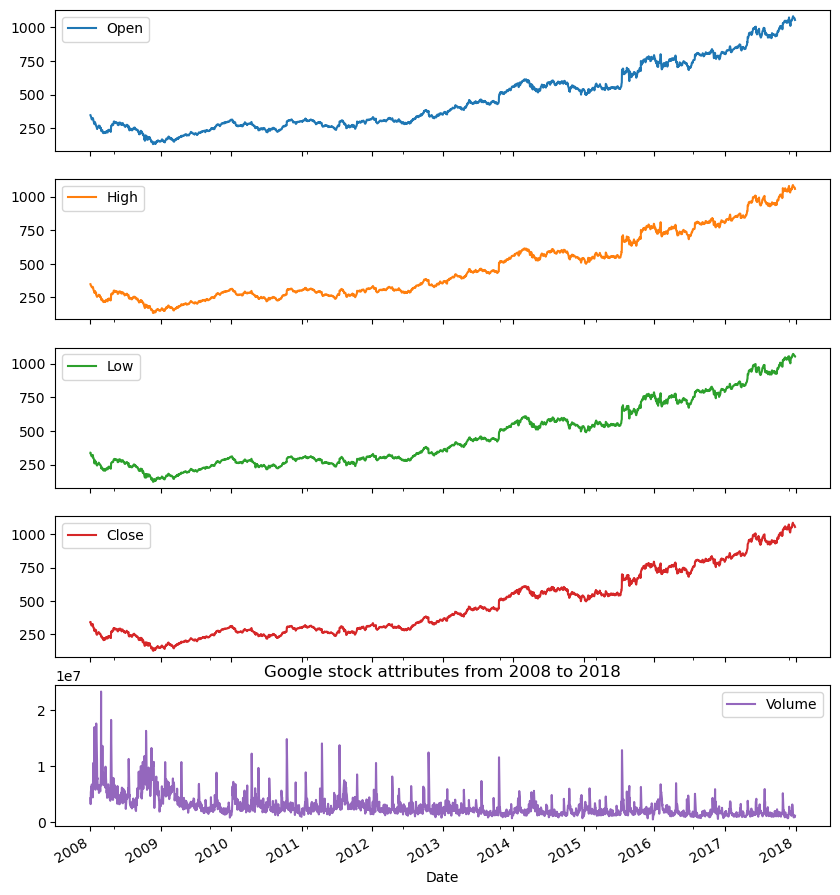

In [22]:
google['2008':'2018'].plot(subplots=True, figsize=(10,12))
plt.title('Google stock attributes from 2008 to 2018')

In [23]:
fig = px.histogram(microsoft, x='Close', marginal='box', nbins=47, title='Distribution of Close')
fig.update_layout(bargap=0.1)

In [24]:
fig = px.histogram(microsoft, x='Open', marginal='box', color_discrete_sequence=['red'], title='Distribution of open')
fig.update_layout(bargap=0.1)

Text(0.5, 1.0, 'Microsoft stock attributes from 2008 to 2018')

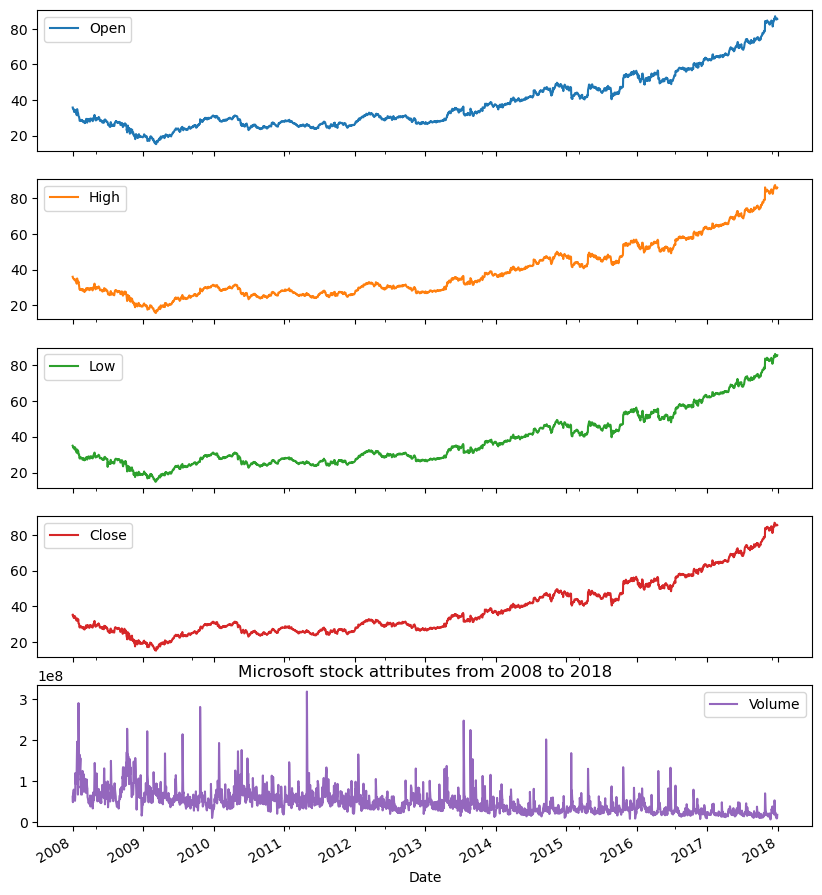

In [25]:
microsoft['2008':'2018'].plot(subplots=True, figsize=(10,12))
plt.title('Microsoft stock attributes from 2008 to 2018')

In [26]:
fig = px.histogram(amazon, x='Close', marginal='box', nbins=47, title='Distribution of Close')
fig.update_layout(bargap=0.1)

In [27]:
fig = px.histogram(amazon, x='Open', marginal='box', color_discrete_sequence=['red'], title='Distribution of open')
fig.update_layout(bargap=0.1)

Text(0.5, 1.0, 'Amazon stock attributes from 2008 to 2018')

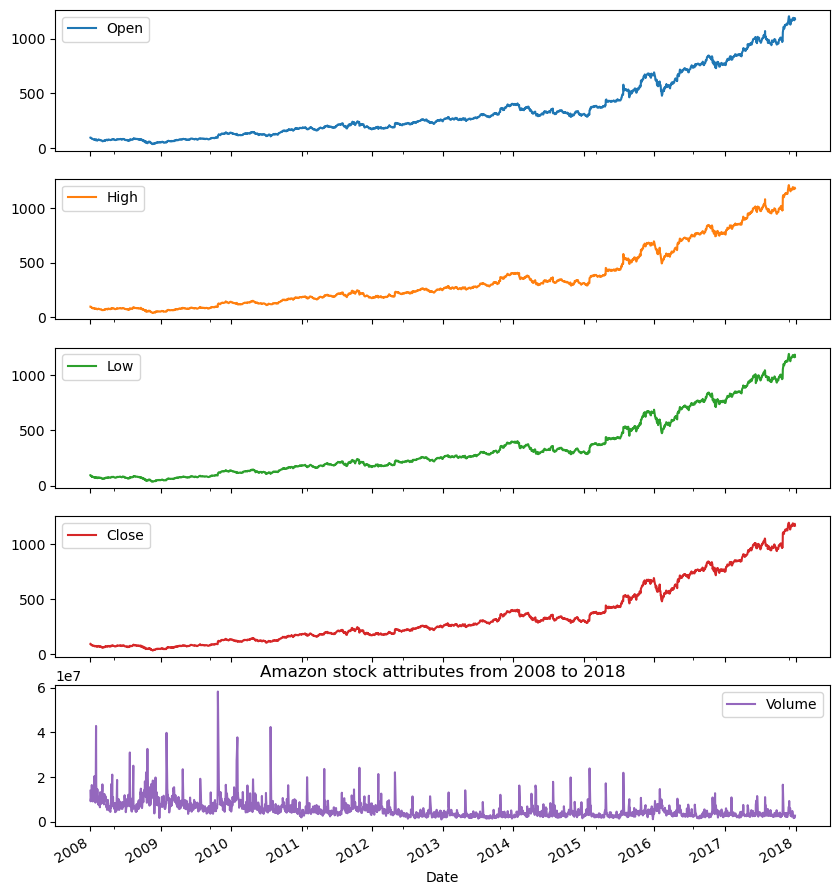

In [28]:
amazon['2008':'2018'].plot(subplots=True, figsize=(10,12))
plt.title('Amazon stock attributes from 2008 to 2018')

In [29]:
fig = px.histogram(ibm, x='Close', marginal='box', nbins=47, title='Distribution of Close')
fig.update_layout(bargap=0.1)

In [30]:
fig = px.histogram(ibm, x='Open', marginal='box', color_discrete_sequence=['red'], title='Distribution of open')
fig.update_layout(bargap=0.1)

Text(0.5, 1.0, 'IBM stock attributes from 2008 to 2018')

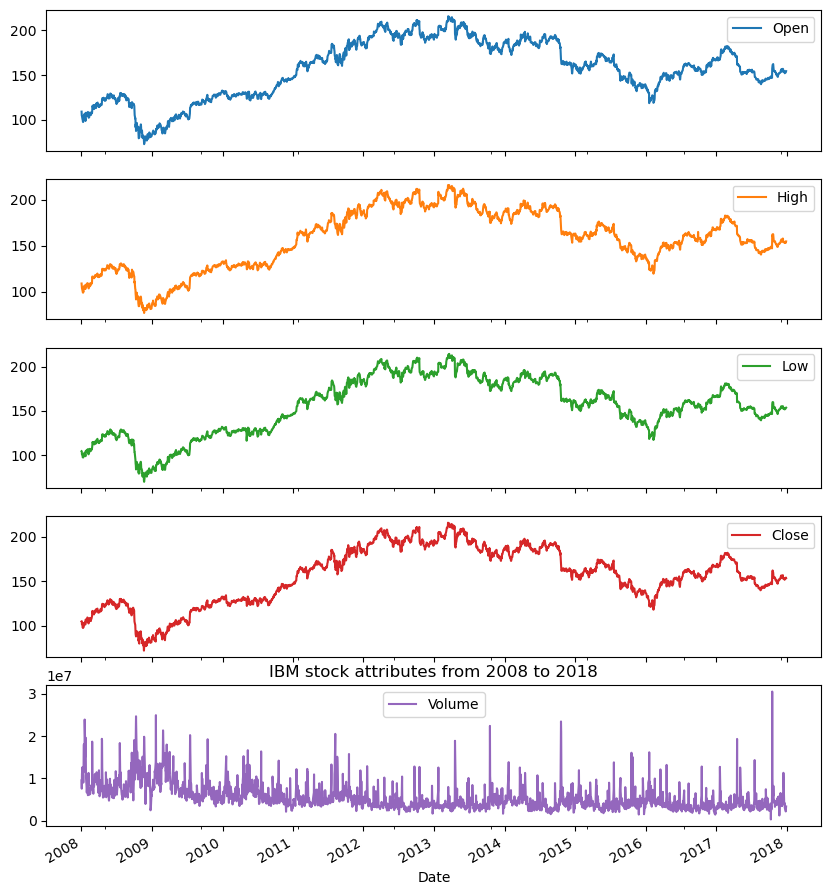

In [31]:
ibm['2008':'2018'].plot(subplots=True, figsize=(10,12))
plt.title('IBM stock attributes from 2008 to 2018')

### High Plot

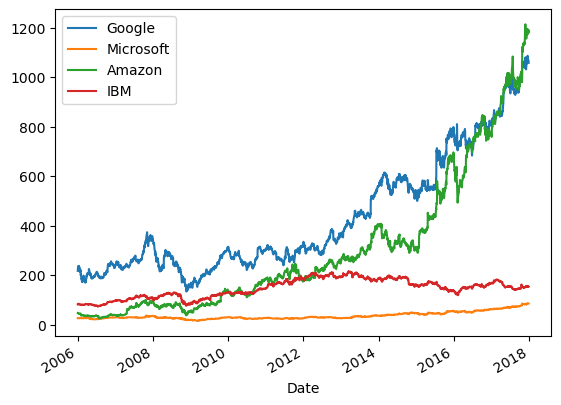

In [32]:
# Plotting before normalization
google.High.plot()
microsoft.High.plot()
amazon.High.plot()
ibm.High.plot()
plt.legend(['Google','Microsoft','Amazon','IBM'])

As we can see here Microsoft's "High" value is very slowly increasing straight line. IBM's "High" value and Amazon's "High" value started from the approx same stage, even Amazon's "High" value was a bit lower but after 2012 Amazon's "High" value started to exponentially increase and slight drop for IBM's "High" value. Since 2016 there is a high fight going between Google's "High" value and Amazon's "High" value at 2018 Amazon's "High" value also beat Google's "High" value.

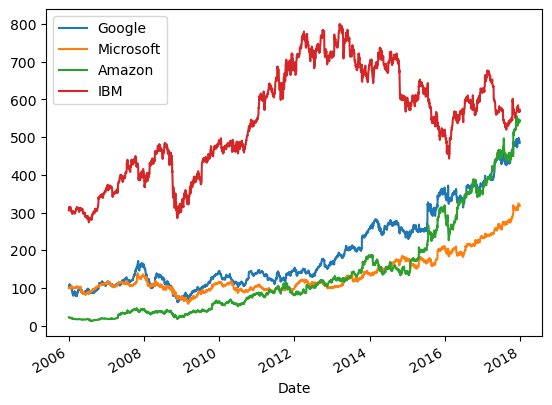

In [33]:
# Normalizing and comparison
# Both stocks start from 100
normalized_google = google.High.div(google.High.iloc[0]).mul(100)
normalized_microsoft = microsoft.High.div(microsoft.High.iloc[0]).mul(100)
normalized_amazon = amazon.High.div(google.High.iloc[0]).mul(100)
normalized_ibm = ibm.High.div(microsoft.High.iloc[0]).mul(100)
normalized_google.plot()
normalized_microsoft.plot()
normalized_amazon.plot()
normalized_ibm.plot()
plt.legend(['Google','Microsoft','Amazon','IBM'])
plt.show()

Text(0.5, 1.0, 'Google')

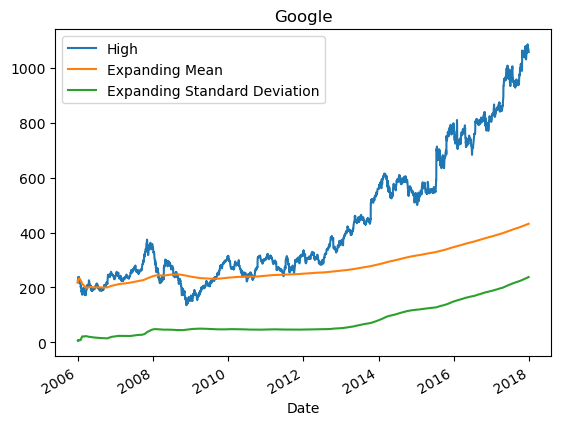

In [34]:
# Expanding window functions
google_mean = google.High.expanding().mean()
google_std = google.High.expanding().std()
google.High.plot()
google_mean.plot()
google_std.plot()
plt.legend(['High','Expanding Mean','Expanding Standard Deviation'])
plt.title('Google')

In Google data, we can see in 2009 "High" value was under mean for a long time, so we can say there was some loss. But it was not an as huge loss as Amazon.

Text(0.5, 1.0, 'Microsoft')

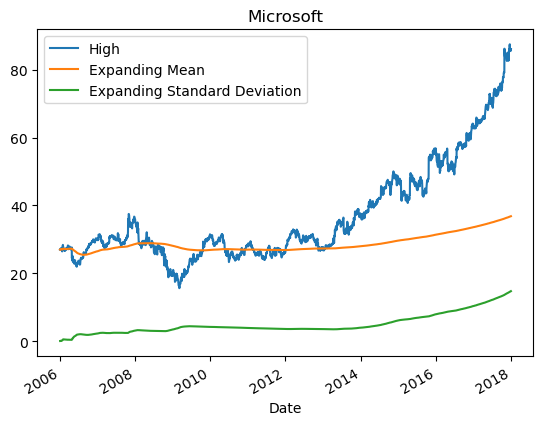

In [34]:
# Expanding window functions
microsoft_mean = microsoft.High.expanding().mean()
microsoft_std = microsoft.High.expanding().std()
microsoft.High.plot()
microsoft_mean.plot()
microsoft_std.plot()
plt.legend(['High','Expanding Mean','Expanding Standard Deviation'])
plt.title('Microsoft')

In Microsoft data, we can see in 2009 "High" value was under mean for a long time, so we can say there was some loss.

Text(0.5, 1.0, 'Amazon')

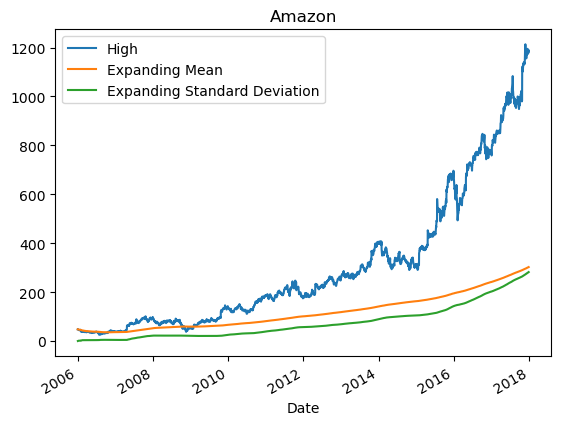

In [35]:
# Expanding window functions
amazon_mean = amazon.High.expanding().mean()
amazon_std = amazon.High.expanding().std()
amazon.High.plot()
amazon_mean.plot()
amazon_std.plot()
plt.legend(['High','Expanding Mean','Expanding Standard Deviation'])
plt.title('Amazon')

For Amazon's "High" value the case is different they also face loss in 2009 but for a very little margin. And after that their growth is in exponential order.

Text(0.5, 1.0, 'IBM')

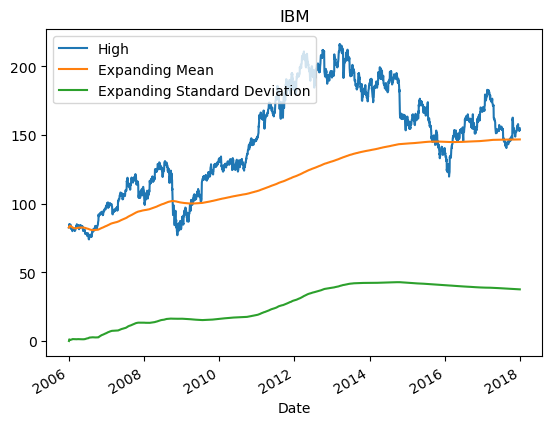

In [36]:
# Expanding window functions
ibm_mean = ibm.High.expanding().mean()
ibm_std = ibm.High.expanding().std()
ibm.High.plot()
ibm_mean.plot()
ibm_std.plot()
plt.legend(['High','Expanding Mean','Expanding Standard Deviation'])
plt.title('IBM')

In IBM data, we can see in 2009 "High" value was under mean for a long time, so we can say there was some loss. And after 2013 again a drop then in 2016 there was a huge loss but after that, they were doing well. After just some profit again in between 2017, there was another drop.

## Here we can see every company faced a loss in 2009, maybe that's because of the economic slowdown.

### Close

Text(0.5, 1.0, 'Google')

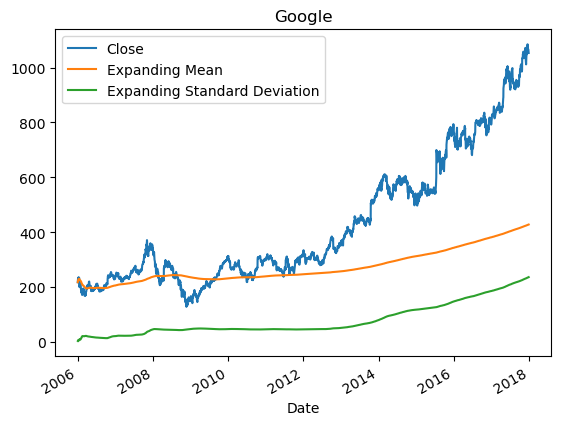

In [37]:
# Expanding window functions
google_mean = google.Close.expanding().mean()
google_std = google.Close.expanding().std()
google.Close.plot()
google_mean.plot()
google_std.plot()
plt.legend(['Close','Expanding Mean','Expanding Standard Deviation'])
plt.title('Google')

Text(0.5, 1.0, 'Microsoft')

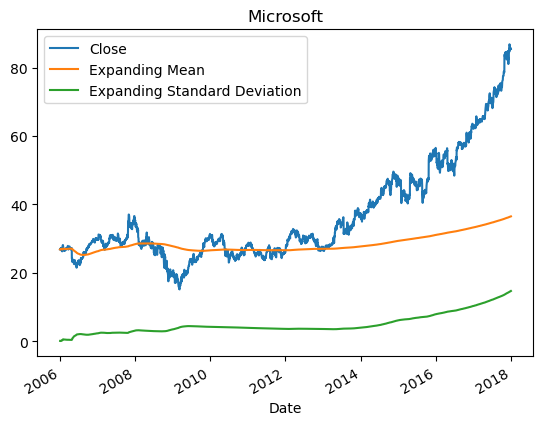

In [38]:
# Expanding window functions
microsoft_mean = microsoft.Close.expanding().mean()
microsoft_std = microsoft.Close.expanding().std()
microsoft.Close.plot()
microsoft_mean.plot()
microsoft_std.plot()
plt.legend(['Close','Expanding Mean','Expanding Standard Deviation'])
plt.title('Microsoft')

Text(0.5, 1.0, 'Amazon')

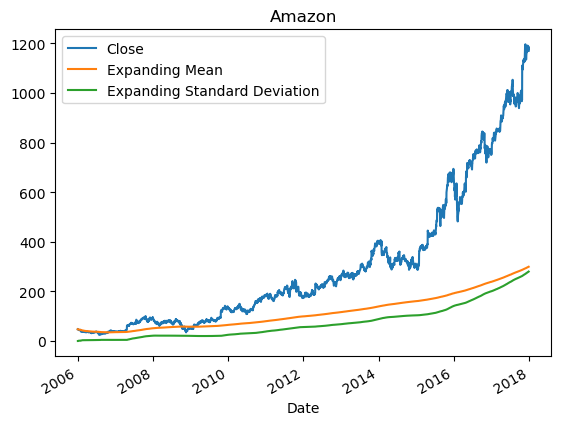

In [39]:
# Expanding window functions
amazon_mean = amazon.Close.expanding().mean()
amazon_std = amazon.Close.expanding().std()
amazon.Close.plot()
amazon_mean.plot()
amazon_std.plot()
plt.legend(['Close','Expanding Mean','Expanding Standard Deviation'])
plt.title('Amazon')

Text(0.5, 1.0, 'IBM')

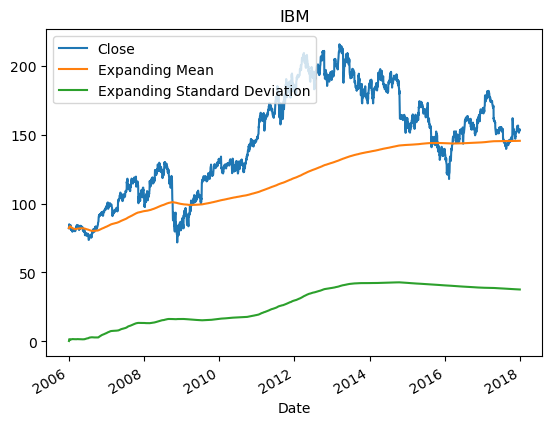

In [40]:
# Expanding window functions
ibm_mean = ibm.Close.expanding().mean()
ibm_std = ibm.Close.expanding().std()
ibm.Close.plot()
ibm_mean.plot()
ibm_std.plot()
plt.legend(['Close','Expanding Mean','Expanding Standard Deviation'])
plt.title('IBM')

## Trend and Seasonality

Google Data

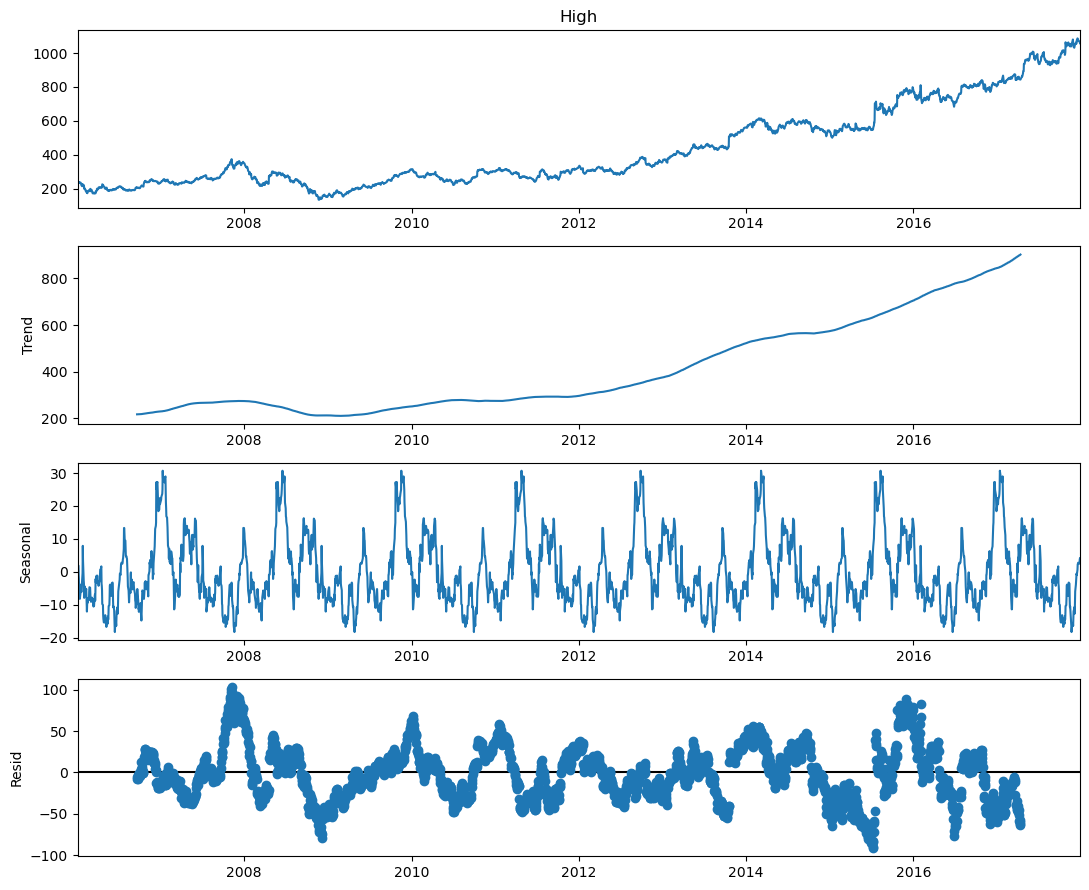

In [41]:
rcParams['figure.figsize'] = 11, 9
decomposed_google_volume = sm.tsa.seasonal_decompose(google["High"], period=360)
figure = decomposed_google_volume.plot()

There is a very slow increasing trend until 2012, but after 2012 there was an exponential high trend. And very high seasonality.

MicroSoft Data

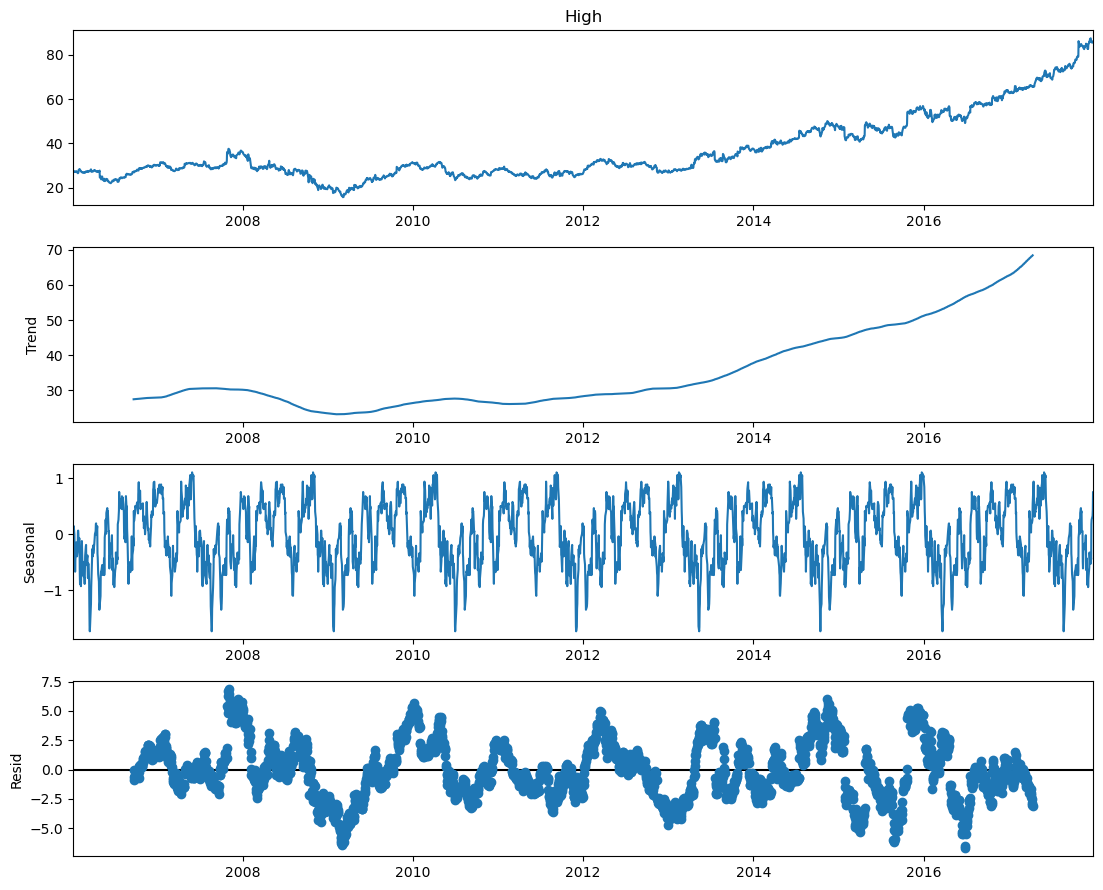

In [42]:
rcParams['figure.figsize'] = 11, 9
decomposed_microsoft_volume = sm.tsa.seasonal_decompose(microsoft["High"],period=360)
figure = decomposed_microsoft_volume.plot()

Same for Microsoft data, there is a very slow increasing trend until 2012, but after 2012 there was an exponential high trend. And very high seasonality.

Amazon Data

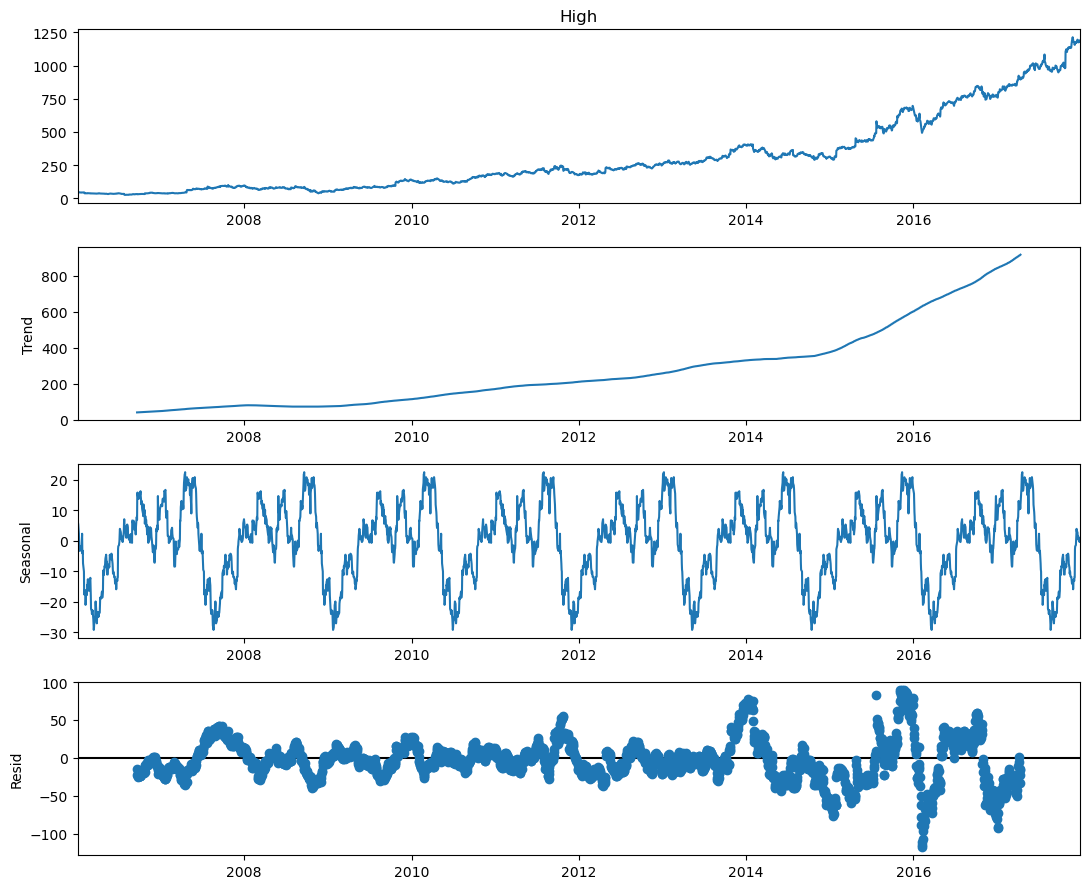

In [43]:
rcParams['figure.figsize'] = 11, 9
decomposed_amazon_volume = sm.tsa.seasonal_decompose(amazon["High"], period=360)
figure = decomposed_amazon_volume.plot()

Amazon data is similar to Google data.

IBM Data

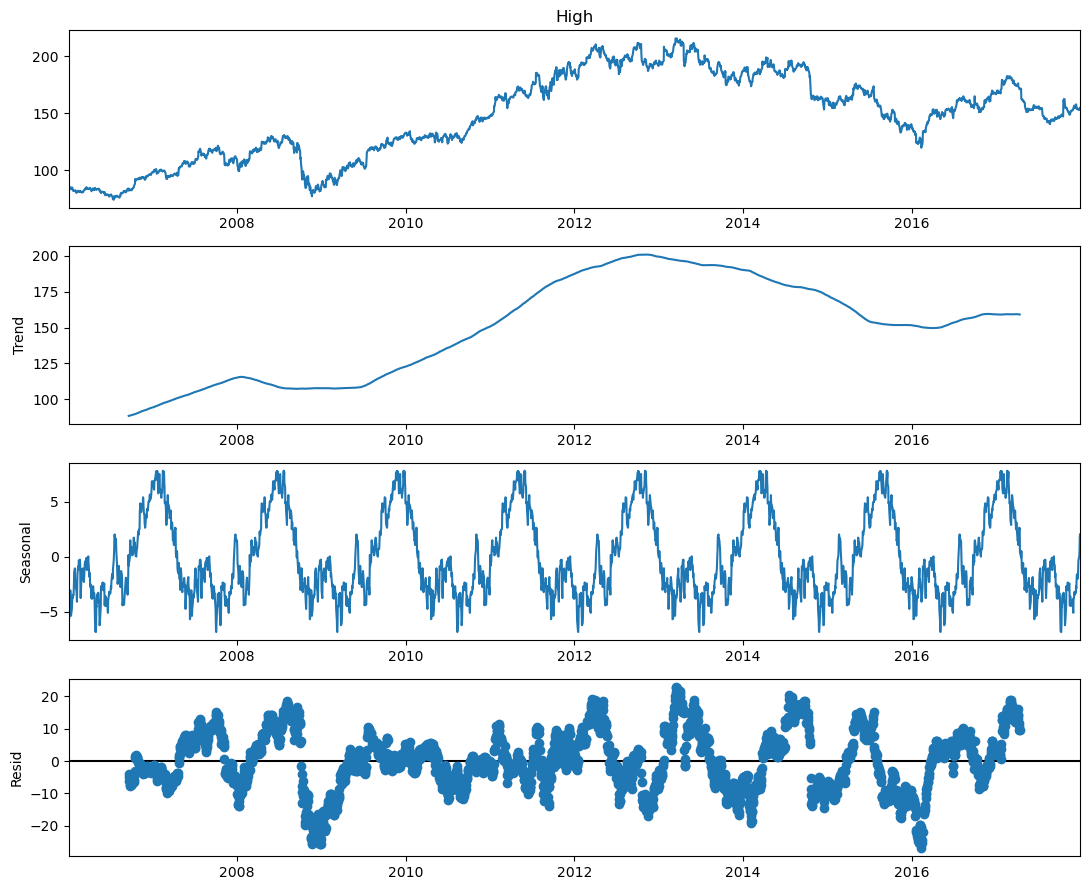

In [44]:
rcParams['figure.figsize'] = 11, 9
decomposed_ibm_volume = sm.tsa.seasonal_decompose(ibm["High"], period=360)
figure = decomposed_ibm_volume.plot()

IBM data has a very slow increasing trend until 2008, but after 2009 there was an exponential high trend until 2013, then a high drop until 2016 then a very slow increasing trend. And very high seasonality.

### Close

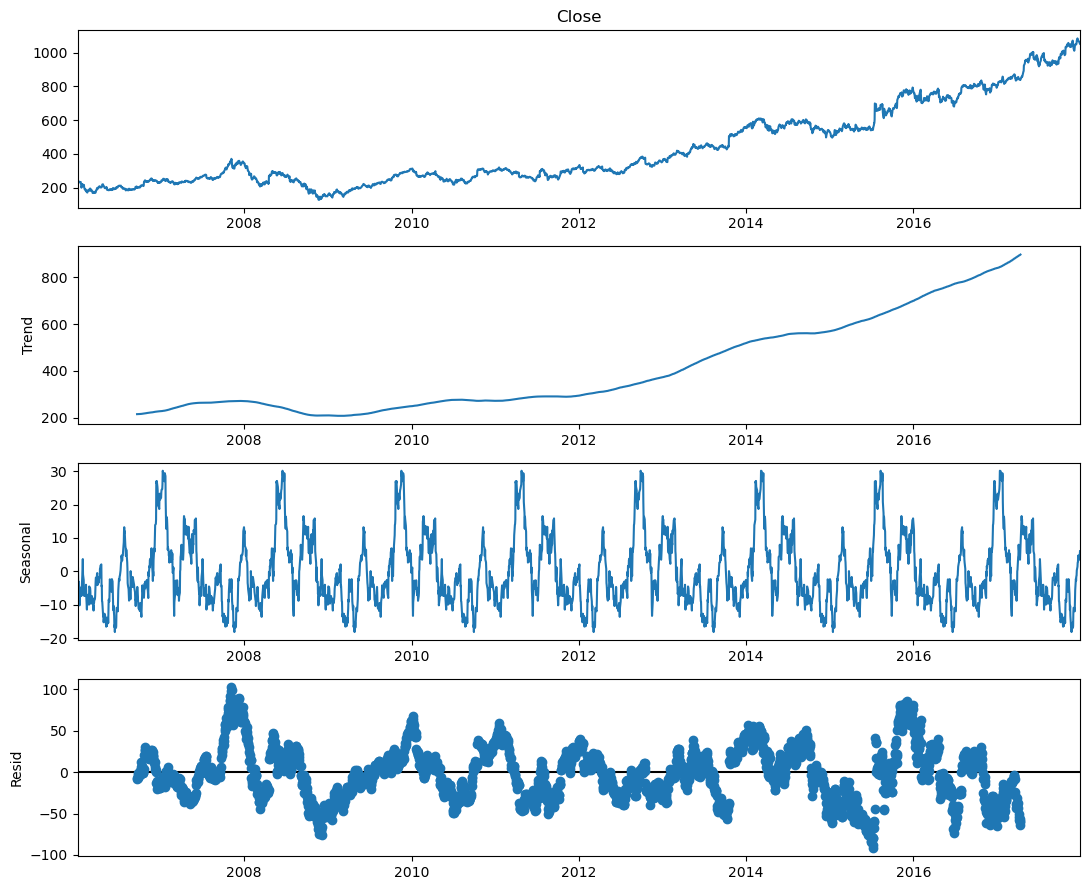

In [45]:
rcParams['figure.figsize'] = 11, 9
decomposed_google_volume = sm.tsa.seasonal_decompose(google["Close"], period=360)
figure = decomposed_google_volume.plot()

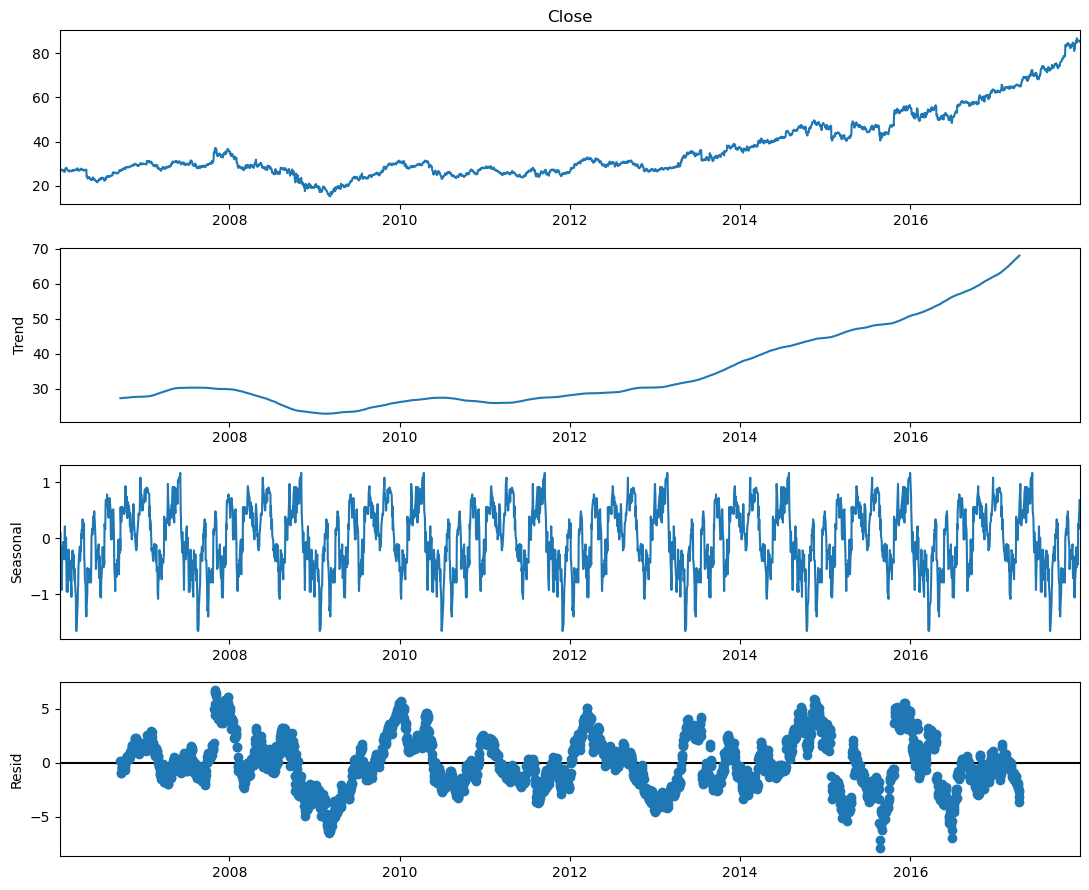

In [46]:
rcParams['figure.figsize'] = 11, 9
decomposed_microsoft_volume = sm.tsa.seasonal_decompose(microsoft["Close"],period=360)
figure = decomposed_microsoft_volume.plot()

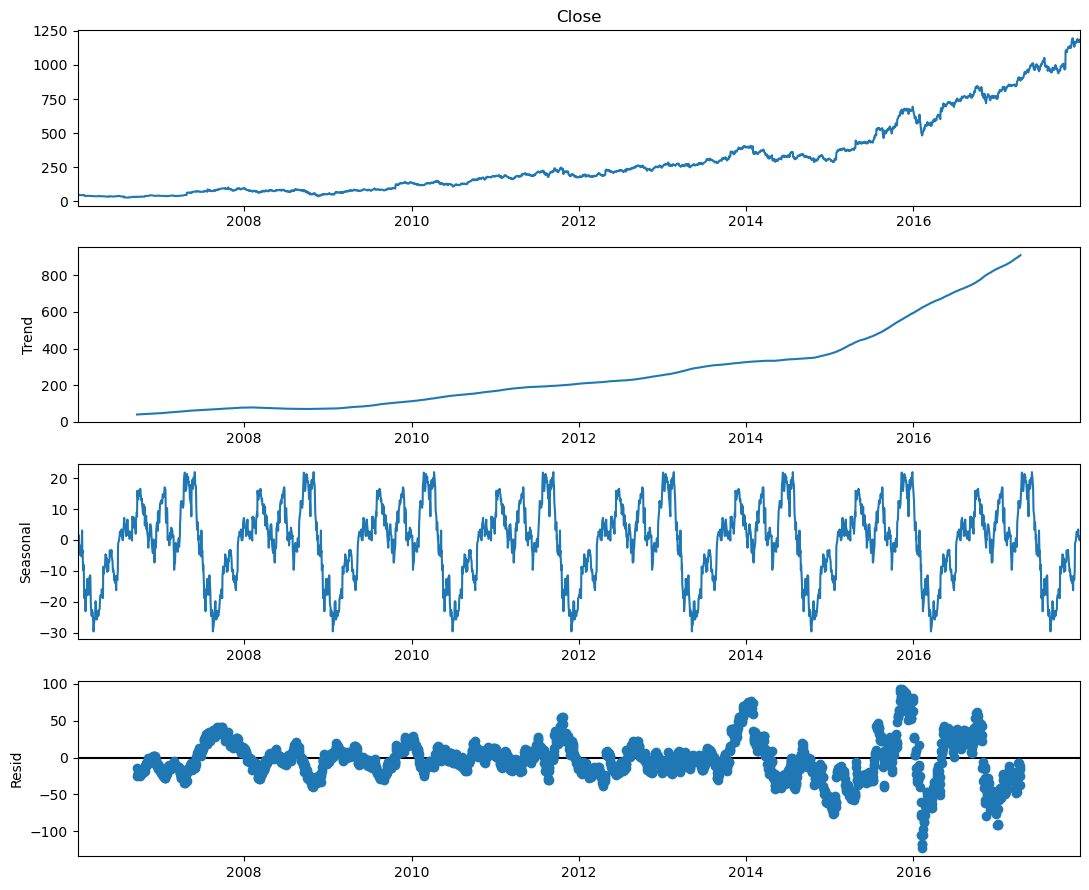

In [47]:
rcParams['figure.figsize'] = 11, 9
decomposed_amazon_volume = sm.tsa.seasonal_decompose(amazon["Close"], period=360)
figure = decomposed_amazon_volume.plot()

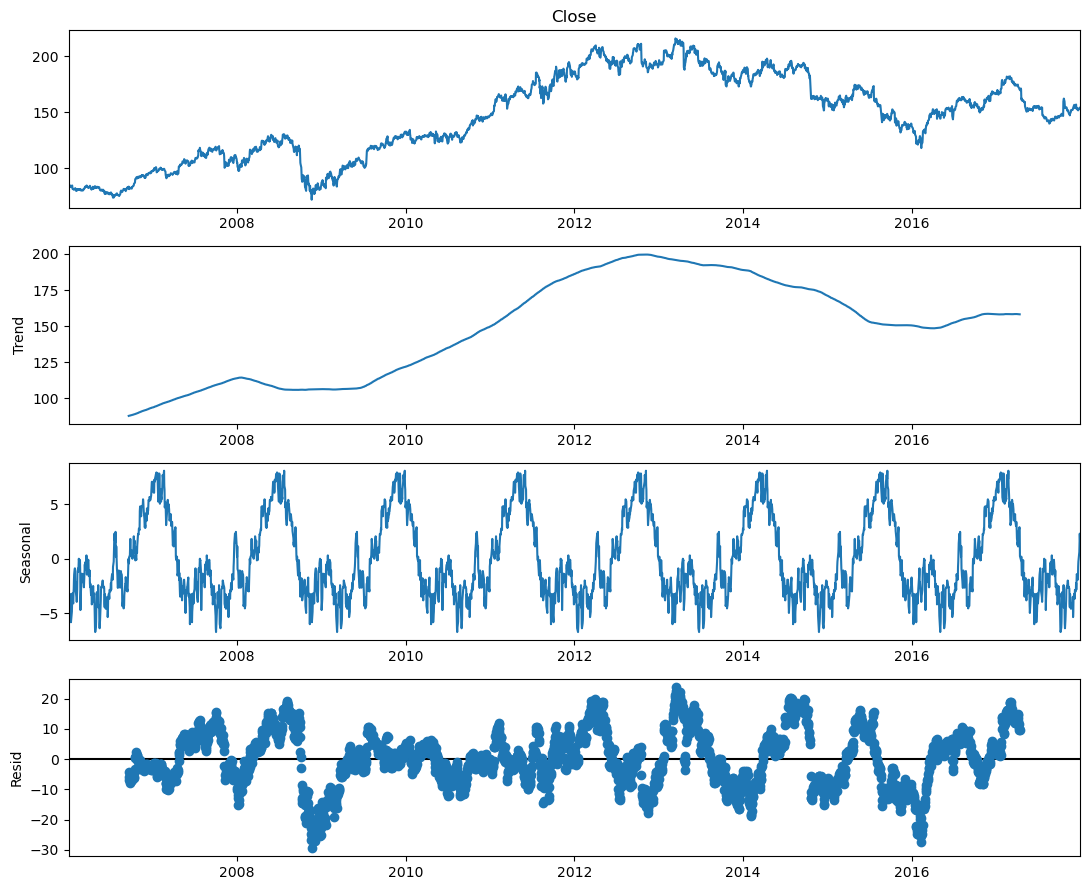

In [48]:
rcParams['figure.figsize'] = 11, 9
decomposed_ibm_volume = sm.tsa.seasonal_decompose(ibm["Close"], period=360)
figure = decomposed_ibm_volume.plot()

Because there have a very strong correlation between Close and High, we can see the trend and seasonality is very similar.

# Prediction

## Time Series Forecasting:
Time series forecasting uses information regarding historical values and associated patterns to predict future activity. Most often, this relates to trend analysis, cyclical fluctuation analysis, and issues of seasonality. As with all forecasting methods, success is not guaranteed.

## GRU Model:
Gated recurrent unit  is essentially a simplified LSTM. It has
the exact same role in the network. The main difference is in the number of
gates and weights — GRU is somewhat simpler. It has 2 gates. Since it does
not have an output gate, there is no control over the memory content. The
update gate controls the information flow from the previous activation, and
the addition of new information as well, while the reset gate is inserted
into the candidate activation.

By using GRU time series forecasting we will forcaste and check.

In [49]:
filepath = 'GOOGL_2006-01-01_to_2018-01-01.csv'
data_google = pd.read_csv(filepath)
data_google = data_google.sort_values('Date')
data_google.head()

,Date,Open,High,Low,Close,Volume,Name
0,2006-01-03,211.47,218.05,209.32,217.83,13137450,GOOGL
1,2006-01-04,222.17,224.70,220.09,222.84,15292353,GOOGL
2,2006-01-05,223.22,226.00,220.97,225.85,10815661,GOOGL
3,2006-01-06,228.66,235.49,226.85,233.06,17759521,GOOGL
4,2006-01-09,233.44,236.94,230.70,233.68,12795837,GOOGL


Text(0, 0.5, 'Close Price (USD)')

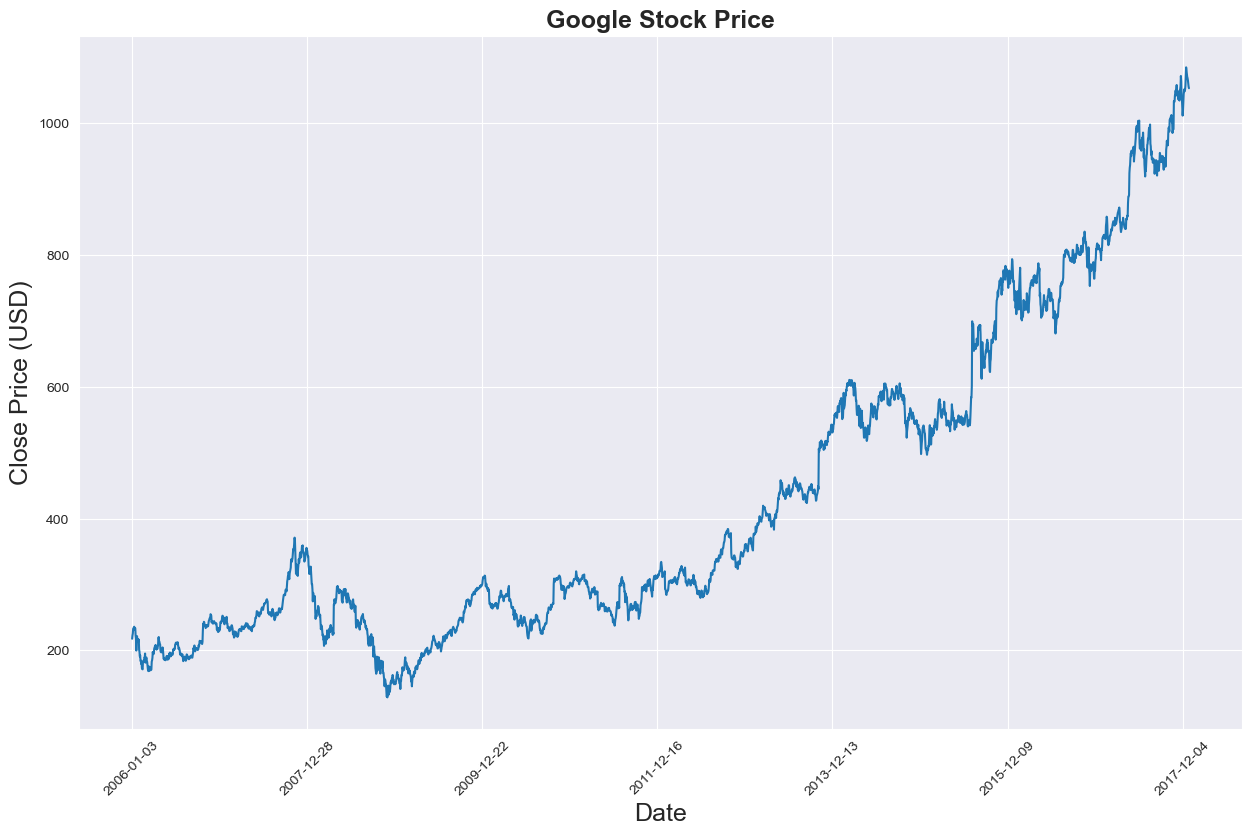

In [50]:
sns.set_style("darkgrid")
plt.figure(figsize = (15,9))
plt.plot(data_google[['Close']])
plt.xticks(range(0,data_google.shape[0],500),data_google['Date'].loc[::500],rotation=45)
plt.title("Google Stock Price",fontsize=18, fontweight='bold')
plt.xlabel('Date',fontsize=18)
plt.ylabel('Close Price (USD)',fontsize=18)

In [51]:
filepath = 'MSFT_2006-01-01_to_2018-01-01.csv'
data_microsoft = pd.read_csv(filepath)
data_microsoft = data_microsoft.sort_values('Date')
data_microsoft.head()

,Date,Open,High,Low,Close,Volume,Name
0,2006-01-03,26.25,27.00,26.10,26.84,79974418,MSFT
1,2006-01-04,26.77,27.08,26.77,26.97,57975661,MSFT
2,2006-01-05,26.96,27.13,26.91,26.99,48247610,MSFT
3,2006-01-06,26.89,27.00,26.49,26.91,100969092,MSFT
4,2006-01-09,26.93,27.07,26.76,26.86,55627836,MSFT


Text(0, 0.5, 'Close Price (USD)')

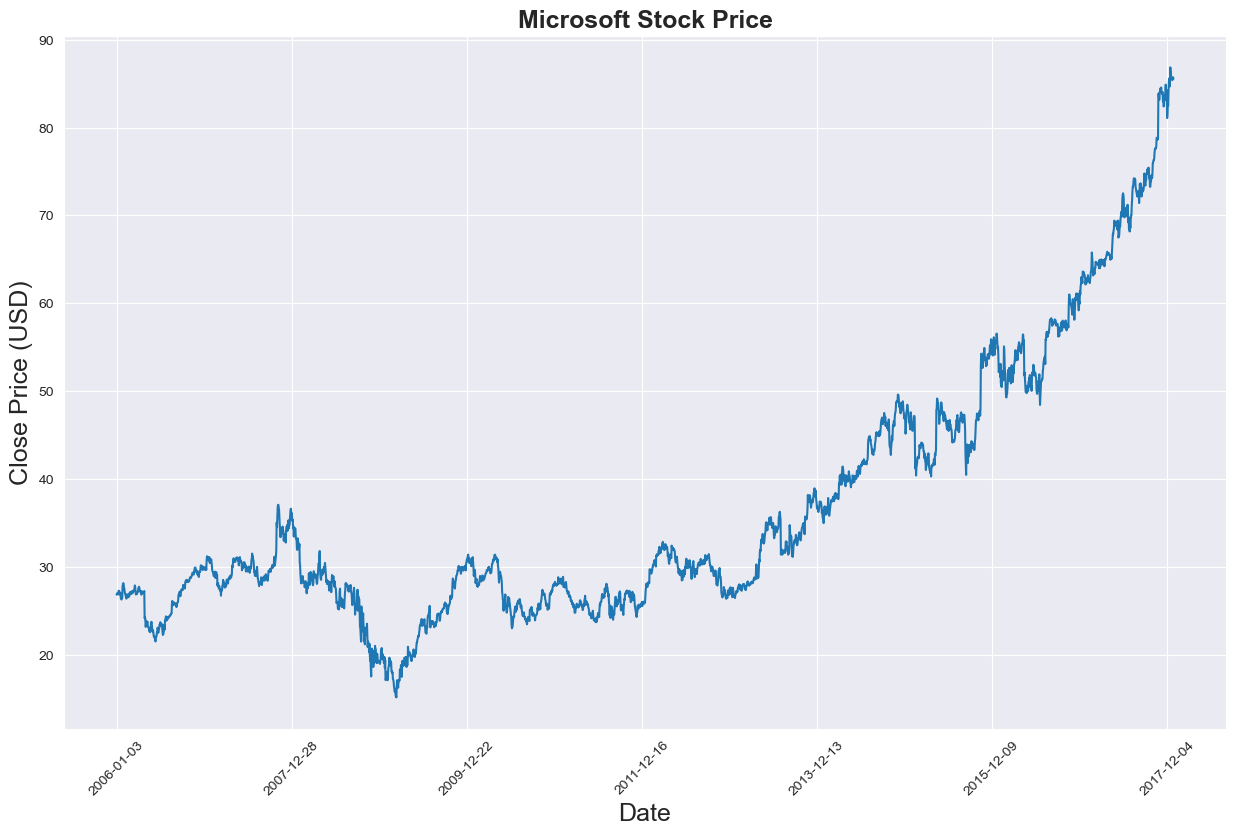

In [52]:
sns.set_style("darkgrid")
plt.figure(figsize = (15,9))
plt.plot(data_microsoft[['Close']])
plt.xticks(range(0,data_microsoft.shape[0],500),data_microsoft['Date'].loc[::500],rotation=45)
plt.title("Microsoft Stock Price",fontsize=18, fontweight='bold')
plt.xlabel('Date',fontsize=18)
plt.ylabel('Close Price (USD)',fontsize=18)

In [53]:
filepath = 'AMZN_2006-01-01_to_2018-01-01.csv'
data_amazon = pd.read_csv(filepath)
data_amazon = data_amazon.sort_values('Date')
data_amazon.head()

,Date,Open,High,Low,Close,Volume,Name
0,2006-01-03,47.47,47.85,46.25,47.58,7582127,AMZN
1,2006-01-04,47.48,47.73,46.69,47.25,7440914,AMZN
2,2006-01-05,47.16,48.20,47.11,47.65,5417258,AMZN
3,2006-01-06,47.97,48.58,47.32,47.87,6154285,AMZN
4,2006-01-09,46.55,47.10,46.40,47.08,8945056,AMZN


Text(0, 0.5, 'Close Price (USD)')

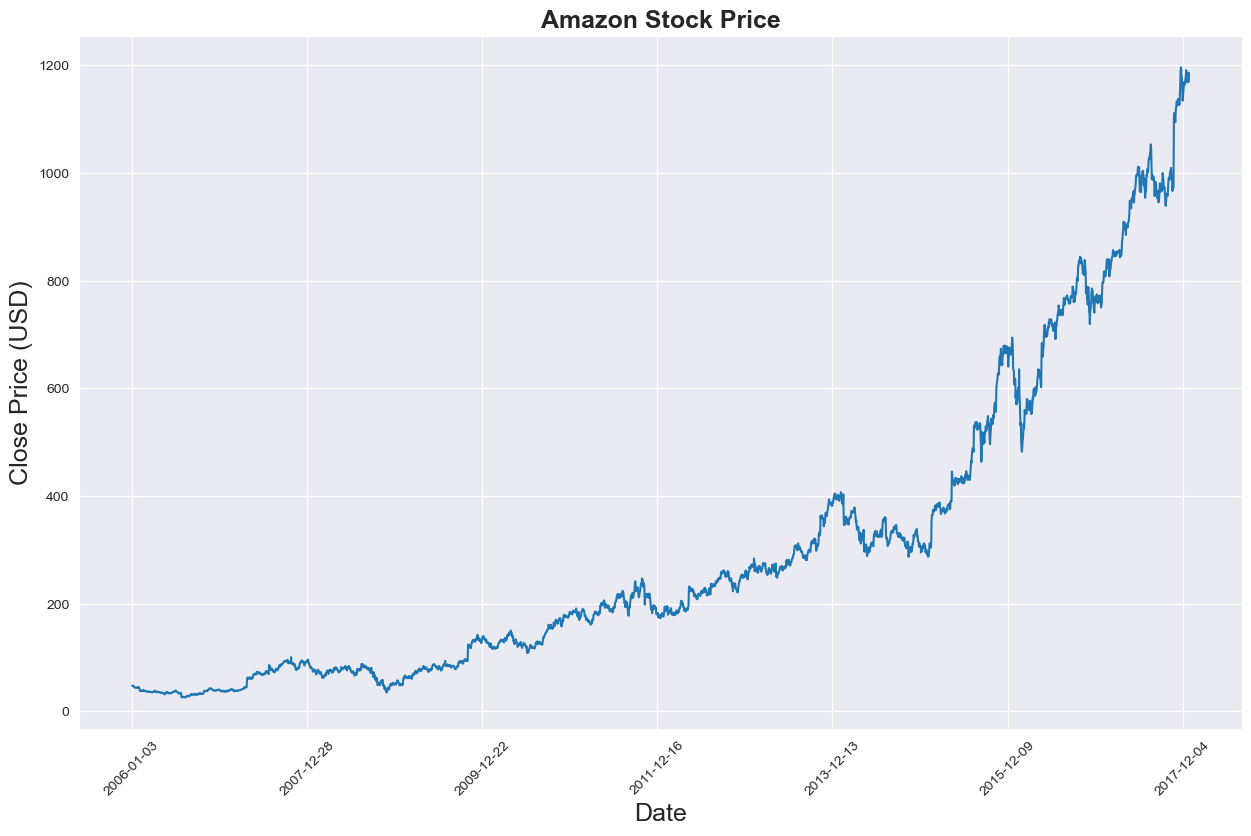

In [54]:
sns.set_style("darkgrid")
plt.figure(figsize = (15,9))
plt.plot(data_amazon[['Close']])
plt.xticks(range(0,data_amazon.shape[0],500),data_amazon['Date'].loc[::500],rotation=45)
plt.title("Amazon Stock Price",fontsize=18, fontweight='bold')
plt.xlabel('Date',fontsize=18)
plt.ylabel('Close Price (USD)',fontsize=18)

In [55]:
filepath = 'IBM_2006-01-01_to_2018-01-01.csv'
data_ibm = pd.read_csv(filepath)
data_ibm = data_ibm.sort_values('Date')
data_ibm.dropna(inplace=True)
data_ibm.head()

,Date,Open,High,Low,Close,Volume,Name
0,2006-01-03,82.45,82.55,80.81,82.06,11715200,IBM
1,2006-01-04,82.20,82.50,81.33,81.95,9840600,IBM
2,2006-01-05,81.40,82.90,81.00,82.50,7213500,IBM
3,2006-01-06,83.95,85.03,83.41,84.95,8197400,IBM
4,2006-01-09,84.10,84.25,83.38,83.73,6858200,IBM


Text(0, 0.5, 'Close Price (USD)')

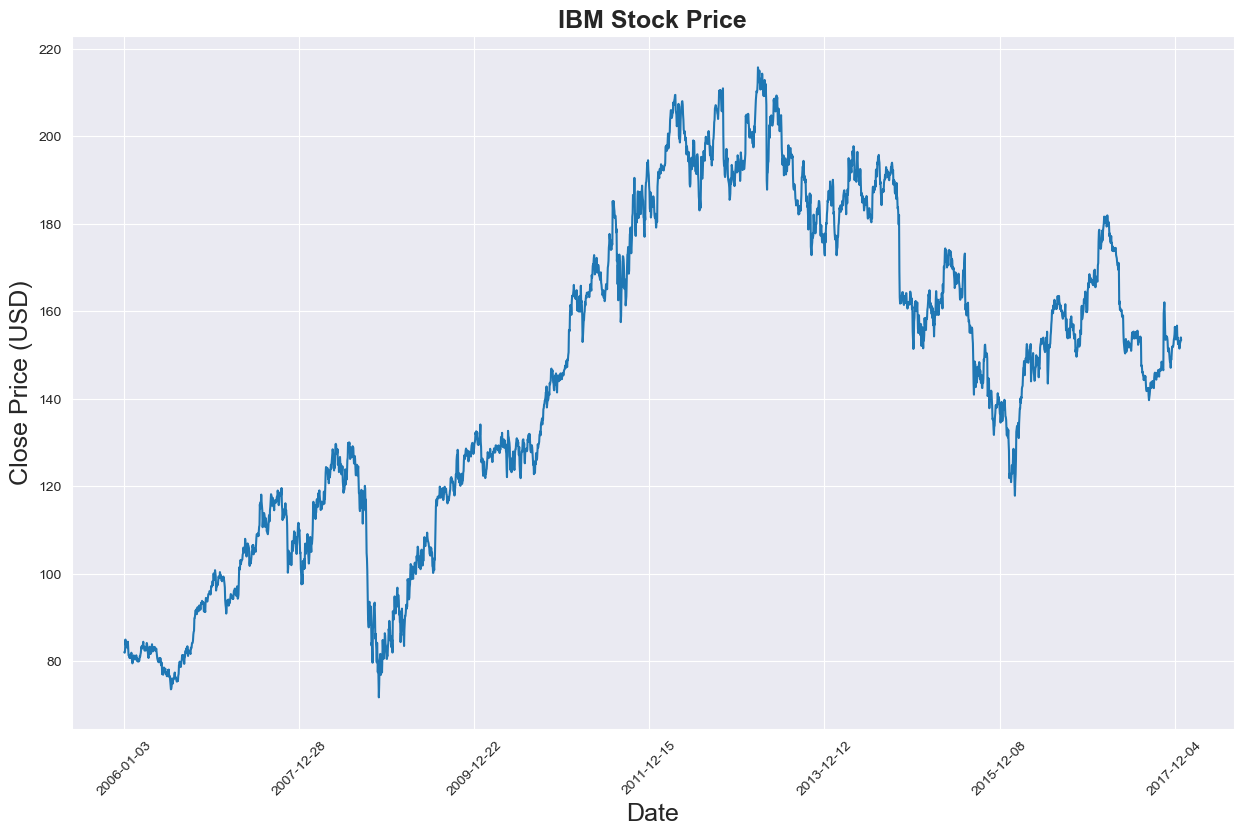

In [56]:
sns.set_style("darkgrid")
plt.figure(figsize = (15,9))
plt.plot(data_ibm[['Close']])
plt.xticks(range(0,data_ibm.shape[0],500),data_ibm['Date'].loc[::500],rotation=45)
plt.title("IBM Stock Price",fontsize=18, fontweight='bold')
plt.xlabel('Date',fontsize=18)
plt.ylabel('Close Price (USD)',fontsize=18)

In [57]:
def split_data(stock, lookback):
    data_raw = stock.to_numpy() # convert to numpy array
    data = []
    
    # create all possible sequences of length seq_len
    for index in range(len(data_raw) - lookback): 
        data.append(data_raw[index: index + lookback])
    
    data = np.array(data)
    test_set_size = int(np.round(0.2*data.shape[0]))
    train_set_size = data.shape[0] - (test_set_size)
    
    x_train = data[:train_set_size,:-1,:]
    y_train = data[:train_set_size,-1,:]
    
    x_test = data[train_set_size:,:-1]
    y_test = data[train_set_size:,-1,:]
    
    return [x_train, y_train, x_test, y_test]

In [58]:
class GRU(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_layers, output_dim):
        super(GRU, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        
        self.gru = nn.GRU(input_dim, hidden_dim, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim).requires_grad_()
        out, (hn) = self.gru(x, (h0.detach()))
        out = self.fc(out[:, -1, :]) 
        return out

In [59]:
price_google = data_google[['Close']]
price_google.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 3019 entries, 0 to 3018
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   3019 non-null   float64
dtypes: float64(1)
memory usage: 47.2 KB


In [60]:
scaler = MinMaxScaler(feature_range=(-1, 1))
price_google['Close'] = scaler.fit_transform(price_google['Close'].values.reshape(-1,1))

C:\Users\pj599\AppData\Local\Temp\ipykernel_19976\3172788508.py:2: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [61]:
lookback = 20
x_train, y_train, x_test, y_test = split_data(price_google, lookback)
print('x_train.shape = ',x_train.shape)
print('y_train.shape = ',y_train.shape)
print('x_test.shape = ',x_test.shape)
print('y_test.shape = ',y_test.shape)

x_train.shape =  (2399, 19, 1)
y_train.shape =  (2399, 1)
x_test.shape =  (600, 19, 1)
y_test.shape =  (600, 1)


In [62]:
x_train = torch.from_numpy(x_train).type(torch.Tensor)
x_test = torch.from_numpy(x_test).type(torch.Tensor)
y_train_lstm = torch.from_numpy(y_train).type(torch.Tensor)
y_test_lstm = torch.from_numpy(y_test).type(torch.Tensor)
y_train_gru = torch.from_numpy(y_train).type(torch.Tensor)
y_test_gru = torch.from_numpy(y_test).type(torch.Tensor)

In [63]:
model = GRU(input_dim=1, hidden_dim=32, output_dim=1, num_layers=2)
criterion = torch.nn.MSELoss(reduction='mean')
optimiser = torch.optim.Adam(model.parameters(), lr=0.01)

In [64]:
hist = np.zeros(105)
start_time = time.time()
gru = []

for t in range(105):
    y_train_pred = model(x_train)

    loss = criterion(y_train_pred, y_train_gru)
    print("Epoch ", t, "MSE: ", loss.item())
    hist[t] = loss.item()

    optimiser.zero_grad()
    loss.backward()
    optimiser.step()

training_time = time.time()-start_time    
print("Training time: {}".format(training_time))

Epoch  0 MSE:  0.3986302614212036
Epoch  1 MSE:  0.08473551273345947
Epoch  2 MSE:  0.2103244960308075
Epoch  3 MSE:  0.11868541687726974
Epoch  4 MSE:  0.06338133662939072
Epoch  5 MSE:  0.07055488228797913
Epoch  6 MSE:  0.08834690600633621
Epoch  7 MSE:  0.09414894878864288
Epoch  8 MSE:  0.08624058961868286
Epoch  9 MSE:  0.07008475065231323
Epoch  10 MSE:  0.05278516188263893
Epoch  11 MSE:  0.041122835129499435
Epoch  12 MSE:  0.03941379114985466
Epoch  13 MSE:  0.045751918107271194
Epoch  14 MSE:  0.0505513958632946
Epoch  15 MSE:  0.04586917534470558
Epoch  16 MSE:  0.034598175436258316
Epoch  17 MSE:  0.024806760251522064
Epoch  18 MSE:  0.020916685461997986
Epoch  19 MSE:  0.021705659106373787
Epoch  20 MSE:  0.022969193756580353
Epoch  21 MSE:  0.020781036466360092
Epoch  22 MSE:  0.014002222567796707
Epoch  23 MSE:  0.005651119630783796
Epoch  24 MSE:  0.002015989739447832
Epoch  25 MSE:  0.006309947464615107
Epoch  26 MSE:  0.009649180807173252
Epoch  27 MSE:  0.0052695139

In [65]:
predict = pd.DataFrame(scaler.inverse_transform(y_train_pred.detach().numpy()))
original = pd.DataFrame(scaler.inverse_transform(y_train_gru.detach().numpy()))

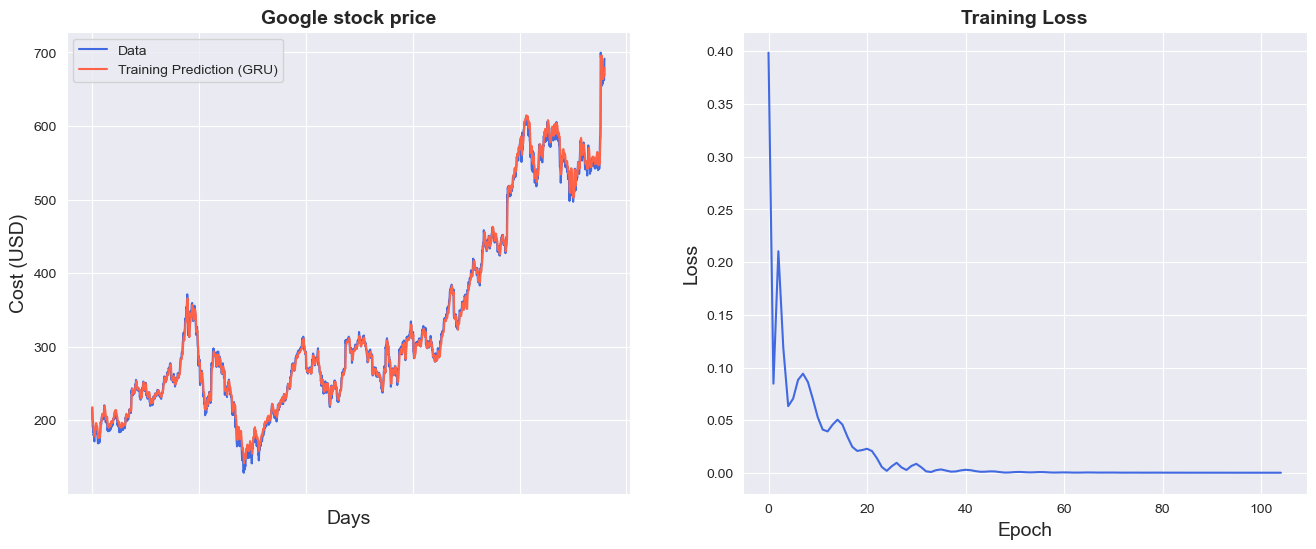

In [66]:
sns.set_style("darkgrid")    

fig = plt.figure()
fig.subplots_adjust(hspace=0.2, wspace=0.2)

plt.subplot(1, 2, 1)
ax = sns.lineplot(x = original.index, y = original[0], label="Data", color='royalblue')
ax = sns.lineplot(x = predict.index, y = predict[0], label="Training Prediction (GRU)", color='tomato')
ax.set_title('Google stock price', size = 14, fontweight='bold')
ax.set_xlabel("Days", size = 14)
ax.set_ylabel("Cost (USD)", size = 14)
ax.set_xticklabels('', size=10)


plt.subplot(1, 2, 2)
ax = sns.lineplot(data=hist, color='royalblue')
ax.set_xlabel("Epoch", size = 14)
ax.set_ylabel("Loss", size = 14)
ax.set_title("Training Loss", size = 14, fontweight='bold')
fig.set_figheight(6)
fig.set_figwidth(16)

In [67]:
# make predictions
y_test_pred = model(x_test)

# invert predictions
y_train_pred = scaler.inverse_transform(y_train_pred.detach().numpy())
y_train = scaler.inverse_transform(y_train_gru.detach().numpy())
y_test_pred = scaler.inverse_transform(y_test_pred.detach().numpy())
y_test = scaler.inverse_transform(y_test_gru.detach().numpy())

# calculate root mean squared error
trainScore = math.sqrt(mean_squared_error(y_train[:,0], y_train_pred[:,0]))
print('Train Score: %.2f RMSE' % (trainScore))
testScore = math.sqrt(mean_squared_error(y_test[:,0], y_test_pred[:,0]))
print('Test Score: %.2f RMSE' % (testScore))
gru.append(trainScore)
gru.append(testScore)
gru.append(training_time)

Train Score: 7.30 RMSE
Test Score: 27.81 RMSE


In [68]:
# shift train predictions for plotting
trainPredictPlot = np.empty_like(price_google)
trainPredictPlot[:, :] = np.nan
trainPredictPlot[lookback:len(y_train_pred)+lookback, :] = y_train_pred

# shift test predictions for plotting
testPredictPlot = np.empty_like(price_google)
testPredictPlot[:, :] = np.nan
testPredictPlot[len(y_train_pred)+lookback-1:len(price_google)-1, :] = y_test_pred

original = scaler.inverse_transform(price_google['Close'].values.reshape(-1,1))

predictions = np.append(trainPredictPlot, testPredictPlot, axis=1)
predictions = np.append(predictions, original, axis=1)
result = pd.DataFrame(predictions)

In [69]:
fig = go.Figure()
fig.add_trace(go.Scatter(go.Scatter(x=result.index, 
                                    y=result[0],
                                    mode='lines',
                                    name='Train prediction')))
fig.add_trace(go.Scatter(x=result.index, 
                         y=result[1],
                         mode='lines',
                         name='Test prediction'))
fig.add_trace(go.Scatter(go.Scatter(x=result.index, 
                                    y=result[2],
                                    mode='lines',
                                    name='Actual Value')))
fig.update_layout(xaxis=dict(showline=True,
                             showgrid=True,
                             showticklabels=False,
                             linecolor='white',
                             linewidth=2),
                  yaxis=dict(title_text='Close (USD)',
                             titlefont=dict(family='Rockwell',
                                            size=12,
                                            color='white'),
                             showline=True,
                             showgrid=True,
                             showticklabels=True,
                             linecolor='white',
                             linewidth=2,
                             ticks='outside',
                             tickfont=dict(family='Rockwell',
                                           size=12,
                                           color='white')),
                             showlegend=True,
                             template = 'plotly_dark')

annotations = []
annotations.append(dict(xref='paper', 
                        yref='paper', 
                        x=0.0, 
                        y=1.05,
                        xanchor='left', 
                        yanchor='bottom',
                        text='Google Stock Result',
                        font=dict(family='Rockwell',
                                  size=26,color='white'),
                        showarrow=False))
fig.update_layout(annotations=annotations)

fig.show()

In [70]:
price_microsoft = data_microsoft[['Close']]
price_microsoft.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 3019 entries, 0 to 3018
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   3019 non-null   float64
dtypes: float64(1)
memory usage: 47.2 KB


In [71]:
scaler = MinMaxScaler(feature_range=(-1, 1))
price_microsoft['Close'] = scaler.fit_transform(price_microsoft['Close'].values.reshape(-1,1))

C:\Users\pj599\AppData\Local\Temp\ipykernel_19976\2369576709.py:2: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [72]:
lookback = 20
x_train, y_train, x_test, y_test = split_data(price_microsoft, lookback)
print('x_train.shape = ',x_train.shape)
print('y_train.shape = ',y_train.shape)
print('x_test.shape = ',x_test.shape)
print('y_test.shape = ',y_test.shape)

x_train.shape =  (2399, 19, 1)
y_train.shape =  (2399, 1)
x_test.shape =  (600, 19, 1)
y_test.shape =  (600, 1)


In [73]:
x_train = torch.from_numpy(x_train).type(torch.Tensor)
x_test = torch.from_numpy(x_test).type(torch.Tensor)
y_train_gru = torch.from_numpy(y_train).type(torch.Tensor)
y_test_gru = torch.from_numpy(y_test).type(torch.Tensor)

In [74]:
model = GRU(input_dim=1, hidden_dim=32, output_dim=1, num_layers=2)
criterion = torch.nn.MSELoss(reduction='mean')
optimiser = torch.optim.Adam(model.parameters(), lr=0.01)

In [75]:
hist = np.zeros(105)
start_time = time.time()
gru = []

for t in range(105):
    y_train_pred = model(x_train)

    loss = criterion(y_train_pred, y_train_gru)
    print("Epoch ", t, "MSE: ", loss.item())
    hist[t] = loss.item()

    optimiser.zero_grad()
    loss.backward()
    optimiser.step()

training_time = time.time()-start_time    
print("Training time: {}".format(training_time))

Epoch  0 MSE:  0.2685525417327881
Epoch  1 MSE:  0.07120602577924728
Epoch  2 MSE:  0.03891097381711006
Epoch  3 MSE:  0.07125665247440338
Epoch  4 MSE:  0.045629292726516724
Epoch  5 MSE:  0.030800556764006615
Epoch  6 MSE:  0.03705774247646332
Epoch  7 MSE:  0.04549124091863632
Epoch  8 MSE:  0.04582183063030243
Epoch  9 MSE:  0.03930169716477394
Epoch  10 MSE:  0.031082158908247948
Epoch  11 MSE:  0.0258492399007082
Epoch  12 MSE:  0.025692161172628403
Epoch  13 MSE:  0.028501706197857857
Epoch  14 MSE:  0.029226623475551605
Epoch  15 MSE:  0.025436444208025932
Epoch  16 MSE:  0.019880961626768112
Epoch  17 MSE:  0.016577744856476784
Epoch  18 MSE:  0.016504190862178802
Epoch  19 MSE:  0.016830667853355408
Epoch  20 MSE:  0.014039690606296062
Epoch  21 MSE:  0.008394895121455193
Epoch  22 MSE:  0.004567980766296387
Epoch  23 MSE:  0.005612284876406193
Epoch  24 MSE:  0.00509984977543354
Epoch  25 MSE:  0.0011081427801400423
Epoch  26 MSE:  0.004836662672460079
Epoch  27 MSE:  0.0069

In [76]:
predict = pd.DataFrame(scaler.inverse_transform(y_train_pred.detach().numpy()))
original = pd.DataFrame(scaler.inverse_transform(y_train_gru.detach().numpy()))

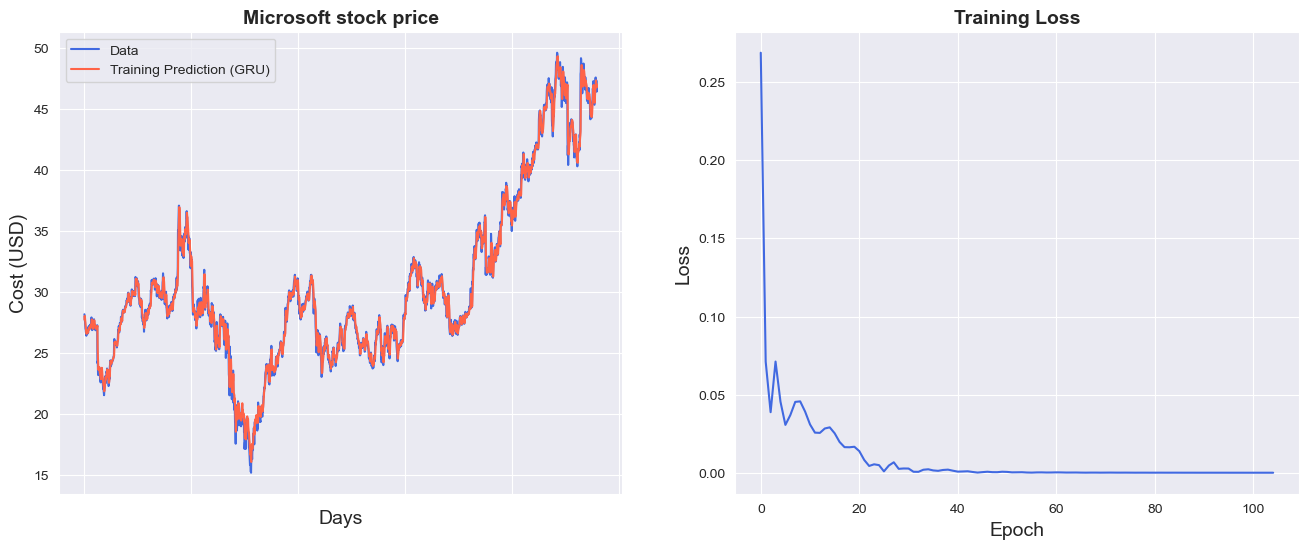

In [77]:
sns.set_style("darkgrid")    

fig = plt.figure()
fig.subplots_adjust(hspace=0.2, wspace=0.2)

plt.subplot(1, 2, 1)
ax = sns.lineplot(x = original.index, y = original[0], label="Data", color='royalblue')
ax = sns.lineplot(x = predict.index, y = predict[0], label="Training Prediction (GRU)", color='tomato')
ax.set_title('Microsoft stock price', size = 14, fontweight='bold')
ax.set_xlabel("Days", size = 14)
ax.set_ylabel("Cost (USD)", size = 14)
ax.set_xticklabels('', size=10)


plt.subplot(1, 2, 2)
ax = sns.lineplot(data=hist, color='royalblue')
ax.set_xlabel("Epoch", size = 14)
ax.set_ylabel("Loss", size = 14)
ax.set_title("Training Loss", size = 14, fontweight='bold')
fig.set_figheight(6)
fig.set_figwidth(16)

In [78]:
# make predictions
y_test_pred = model(x_test)

# invert predictions
y_train_pred = scaler.inverse_transform(y_train_pred.detach().numpy())
y_train = scaler.inverse_transform(y_train_gru.detach().numpy())
y_test_pred = scaler.inverse_transform(y_test_pred.detach().numpy())
y_test = scaler.inverse_transform(y_test_gru.detach().numpy())

# calculate root mean squared error
trainScore = math.sqrt(mean_squared_error(y_train[:,0], y_train_pred[:,0]))
print('Train Score: %.2f RMSE' % (trainScore))
testScore = math.sqrt(mean_squared_error(y_test[:,0], y_test_pred[:,0]))
print('Test Score: %.2f RMSE' % (testScore))
gru.append(trainScore)
gru.append(testScore)
gru.append(training_time)

Train Score: 0.56 RMSE
Test Score: 3.40 RMSE


In [79]:
# shift train predictions for plotting
trainPredictPlot = np.empty_like(price_microsoft)
trainPredictPlot[:, :] = np.nan
trainPredictPlot[lookback:len(y_train_pred)+lookback, :] = y_train_pred

# shift test predictions for plotting
testPredictPlot = np.empty_like(price_microsoft)
testPredictPlot[:, :] = np.nan
testPredictPlot[len(y_train_pred)+lookback-1:len(price_microsoft)-1, :] = y_test_pred

original = scaler.inverse_transform(price_microsoft['Close'].values.reshape(-1,1))

predictions = np.append(trainPredictPlot, testPredictPlot, axis=1)
predictions = np.append(predictions, original, axis=1)
result = pd.DataFrame(predictions)

In [80]:
fig = go.Figure()
fig.add_trace(go.Scatter(go.Scatter(x=result.index, 
                                    y=result[0],
                                    mode='lines',
                                    name='Train prediction')))
fig.add_trace(go.Scatter(x=result.index, y=result[1],
                         mode='lines',
                         name='Test prediction'))
fig.add_trace(go.Scatter(go.Scatter(x=result.index, y=result[2],
                                    mode='lines',
                                    name='Actual Value')))
fig.update_layout(xaxis=dict(showline=True,
                             showgrid=True,
                             showticklabels=False,
                             linecolor='white',
                             linewidth=2), 
                  yaxis=dict(title_text='Close (USD)',
                             titlefont=dict(family='Rockwell',size=12,color='white'),
                             showline=True,
                             showgrid=True,
                             showticklabels=True,
                             linecolor='white',
                             linewidth=2,
                             ticks='outside',
                             tickfont=dict(family='Rockwell',
                                           size=12,
                                           color='white',)),
                            showlegend=True,
                            template = 'plotly_dark')

annotations = []
annotations.append(dict(xref='paper', 
                        yref='paper', 
                        x=0.0, 
                        y=1.05,
                        xanchor='left', 
                        yanchor='bottom',
                        text='Microsoft Stock Prediction',
                        font=dict(family='Rockwell',
                                  size=26,
                                  color='white'),
                        showarrow=False))
fig.update_layout(annotations=annotations)

fig.show()

In [81]:
price_amazon = data_amazon[['Close']]
price_amazon.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 3019 entries, 0 to 3018
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   3019 non-null   float64
dtypes: float64(1)
memory usage: 47.2 KB


In [82]:
scaler = MinMaxScaler(feature_range=(-1, 1))
price_amazon['Close'] = scaler.fit_transform(price_amazon['Close'].values.reshape(-1,1))

C:\Users\pj599\AppData\Local\Temp\ipykernel_19976\2301892817.py:2: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [83]:
lookback = 20
x_train, y_train, x_test, y_test = split_data(price_amazon, lookback)
print('x_train.shape = ',x_train.shape)
print('y_train.shape = ',y_train.shape)
print('x_test.shape = ',x_test.shape)
print('y_test.shape = ',y_test.shape)

x_train.shape =  (2399, 19, 1)
y_train.shape =  (2399, 1)
x_test.shape =  (600, 19, 1)
y_test.shape =  (600, 1)


In [84]:
x_train = torch.from_numpy(x_train).type(torch.Tensor)
x_test = torch.from_numpy(x_test).type(torch.Tensor)
y_train_gru = torch.from_numpy(y_train).type(torch.Tensor)
y_test_gru = torch.from_numpy(y_test).type(torch.Tensor)

In [85]:
model = GRU(input_dim=1, hidden_dim=32, output_dim=1, num_layers=2)
criterion = torch.nn.MSELoss(reduction='mean')
optimiser = torch.optim.Adam(model.parameters(), lr=0.01)

In [86]:
hist = np.zeros(105)
start_time = time.time()
gru = []

for t in range(105):
    y_train_pred = model(x_train)

    loss = criterion(y_train_pred, y_train_gru)
    print("Epoch ", t, "MSE: ", loss.item())
    hist[t] = loss.item()

    optimiser.zero_grad()
    loss.backward()
    optimiser.step()

training_time = time.time()-start_time    
print("Training time: {}".format(training_time))

Epoch  0 MSE:  0.551581084728241
Epoch  1 MSE:  0.20526739954948425
Epoch  2 MSE:  0.028789468109607697
Epoch  3 MSE:  0.1732102483510971
Epoch  4 MSE:  0.08230741322040558
Epoch  5 MSE:  0.02580396458506584
Epoch  6 MSE:  0.04601763188838959
Epoch  7 MSE:  0.07097021490335464
Epoch  8 MSE:  0.07000066339969635
Epoch  9 MSE:  0.051166120916604996
Epoch  10 MSE:  0.030401429161429405
Epoch  11 MSE:  0.020355261862277985
Epoch  12 MSE:  0.025372765958309174
Epoch  13 MSE:  0.03631692752242088
Epoch  14 MSE:  0.038453057408332825
Epoch  15 MSE:  0.030130812898278236
Epoch  16 MSE:  0.02028832770884037
Epoch  17 MSE:  0.015918556600809097
Epoch  18 MSE:  0.017353221774101257
Epoch  19 MSE:  0.020947251468896866
Epoch  20 MSE:  0.022901879623532295
Epoch  21 MSE:  0.021337762475013733
Epoch  22 MSE:  0.016751743853092194
Epoch  23 MSE:  0.011510703712701797
Epoch  24 MSE:  0.008550634607672691
Epoch  25 MSE:  0.00922464020550251
Epoch  26 MSE:  0.011401310563087463
Epoch  27 MSE:  0.0110073

In [87]:
predict = pd.DataFrame(scaler.inverse_transform(y_train_pred.detach().numpy()))
original = pd.DataFrame(scaler.inverse_transform(y_train_gru.detach().numpy()))

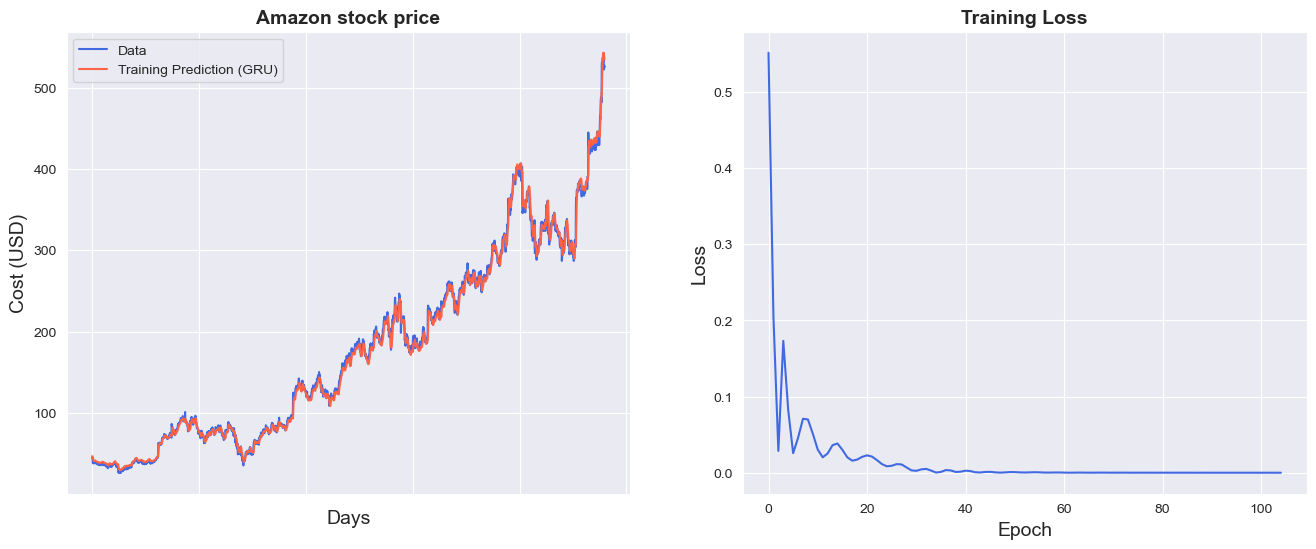

In [88]:
sns.set_style("darkgrid")    

fig = plt.figure()
fig.subplots_adjust(hspace=0.2, wspace=0.2)

plt.subplot(1, 2, 1)
ax = sns.lineplot(x = original.index, y = original[0], label="Data", color='royalblue')
ax = sns.lineplot(x = predict.index, y = predict[0], label="Training Prediction (GRU)", color='tomato')
ax.set_title('Amazon stock price', size = 14, fontweight='bold')
ax.set_xlabel("Days", size = 14)
ax.set_ylabel("Cost (USD)", size = 14)
ax.set_xticklabels('', size=10)


plt.subplot(1, 2, 2)
ax = sns.lineplot(data=hist, color='royalblue')
ax.set_xlabel("Epoch", size = 14)
ax.set_ylabel("Loss", size = 14)
ax.set_title("Training Loss", size = 14, fontweight='bold')
fig.set_figheight(6)
fig.set_figwidth(16)

In [89]:
# make predictions
y_test_pred = model(x_test)

# invert predictions
y_train_pred = scaler.inverse_transform(y_train_pred.detach().numpy())
y_train = scaler.inverse_transform(y_train_gru.detach().numpy())
y_test_pred = scaler.inverse_transform(y_test_pred.detach().numpy())
y_test = scaler.inverse_transform(y_test_gru.detach().numpy())

# calculate root mean squared error
trainScore = math.sqrt(mean_squared_error(y_train[:,0], y_train_pred[:,0]))
print('Train Score: %.2f RMSE' % (trainScore))
testScore = math.sqrt(mean_squared_error(y_test[:,0], y_test_pred[:,0]))
print('Test Score: %.2f RMSE' % (testScore))
gru.append(trainScore)
gru.append(testScore)
gru.append(training_time)

Train Score: 6.07 RMSE
Test Score: 38.28 RMSE


In [90]:
# shift train predictions for plotting
trainPredictPlot = np.empty_like(price_amazon)
trainPredictPlot[:, :] = np.nan
trainPredictPlot[lookback:len(y_train_pred)+lookback, :] = y_train_pred

# shift test predictions for plotting
testPredictPlot = np.empty_like(price_amazon)
testPredictPlot[:, :] = np.nan
testPredictPlot[len(y_train_pred)+lookback-1:len(price_amazon)-1, :] = y_test_pred

original = scaler.inverse_transform(price_amazon['Close'].values.reshape(-1,1))

predictions = np.append(trainPredictPlot, testPredictPlot, axis=1)
predictions = np.append(predictions, original, axis=1)
result = pd.DataFrame(predictions)

In [91]:
fig = go.Figure()
fig.add_trace(go.Scatter(go.Scatter(x=result.index, 
                                    y=result[0],
                                    mode='lines',
                                    name='Train prediction')))
fig.add_trace(go.Scatter(x=result.index, 
                         y=result[1],
                         mode='lines',
                         name='Test prediction'))
fig.add_trace(go.Scatter(go.Scatter(x=result.index, 
                                    y=result[2],
                                    mode='lines',
                                    name='Actual Value')))
fig.update_layout(xaxis=dict(showline=True,
                             showgrid=True,
                             showticklabels=False,
                             linecolor='white',
                             linewidth=2),
                  yaxis=dict(title_text='Close (USD)',
                             titlefont=dict(family='Rockwell',
                                            size=12,
                                            color='white'),
                             showline=True,
                             showgrid=True,
                             showticklabels=True
                             ,linecolor='white',
                             linewidth=2,
                             ticks='outside',
                             tickfont=dict(family='Rockwell',
                                           size=12,
                                           color='white')),
                  showlegend=True,
                  template = 'plotly_dark')

annotations = []
annotations.append(dict(xref='paper', 
                        yref='paper',
                        x=0.0, y=1.05,
                        xanchor='left', 
                        yanchor='bottom',
                        text='Amazon Stock Prediction',
                        font=dict(family='Rockwell',
                                  size=26,
                                  color='white'),
                        showarrow=False))
fig.update_layout(annotations=annotations)

fig.show()

In [92]:
price_ibm = data_ibm[['Close']]
price_ibm.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 3019 entries, 0 to 3019
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   3019 non-null   float64
dtypes: float64(1)
memory usage: 47.2 KB


In [93]:
scaler = MinMaxScaler(feature_range=(-1, 1))
price_ibm['Close'] = scaler.fit_transform(price_ibm['Close'].values.reshape(-1,1))

C:\Users\pj599\AppData\Local\Temp\ipykernel_19976\3610213771.py:2: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [94]:
lookback = 20
x_train, y_train, x_test, y_test = split_data(price_ibm, lookback)
print('x_train.shape = ',x_train.shape)
print('y_train.shape = ',y_train.shape)
print('x_test.shape = ',x_test.shape)
print('y_test.shape = ',y_test.shape)

x_train.shape =  (2399, 19, 1)
y_train.shape =  (2399, 1)
x_test.shape =  (600, 19, 1)
y_test.shape =  (600, 1)


In [95]:
x_train = torch.from_numpy(x_train).type(torch.Tensor)
x_test = torch.from_numpy(x_test).type(torch.Tensor)
y_train_gru = torch.from_numpy(y_train).type(torch.Tensor)
y_test_gru = torch.from_numpy(y_test).type(torch.Tensor)

In [96]:
model = GRU(input_dim=1, hidden_dim=32, output_dim=1, num_layers=2)
criterion = torch.nn.MSELoss(reduction='mean')
optimiser = torch.optim.Adam(model.parameters(), lr=0.01)

In [97]:
hist = np.zeros(105)
start_time = time.time()
gru = []

for t in range(105):
    y_train_pred = model(x_train)

    loss = criterion(y_train_pred, y_train_gru)
    print("Epoch ", t, "MSE: ", loss.item())
    hist[t] = loss.item()

    optimiser.zero_grad()
    loss.backward()
    optimiser.step()

training_time = time.time()-start_time    
print("Training time: {}".format(training_time))

Epoch  0 MSE:  0.32824546098709106
Epoch  1 MSE:  0.23218943178653717
Epoch  2 MSE:  0.13729923963546753
Epoch  3 MSE:  0.032801173627376556
Epoch  4 MSE:  0.05313650518655777
Epoch  5 MSE:  0.06796325743198395
Epoch  6 MSE:  0.013133086264133453
Epoch  7 MSE:  0.006443946622312069
Epoch  8 MSE:  0.02594333328306675
Epoch  9 MSE:  0.03677998483181
Epoch  10 MSE:  0.03403391316533089
Epoch  11 MSE:  0.023817813023924828
Epoch  12 MSE:  0.012782678008079529
Epoch  13 MSE:  0.005355018191039562
Epoch  14 MSE:  0.004404898267239332
Epoch  15 MSE:  0.010638712905347347
Epoch  16 MSE:  0.017171282321214676
Epoch  17 MSE:  0.014626274816691875
Epoch  18 MSE:  0.0063409628346562386
Epoch  19 MSE:  0.0017592428484931588
Epoch  20 MSE:  0.003016391070559621
Epoch  21 MSE:  0.006328030023723841
Epoch  22 MSE:  0.008387408219277859
Epoch  23 MSE:  0.008378633297979832
Epoch  24 MSE:  0.006868418306112289
Epoch  25 MSE:  0.004653394687920809
Epoch  26 MSE:  0.002555904211476445
Epoch  27 MSE:  0.00

In [98]:
predict = pd.DataFrame(scaler.inverse_transform(y_train_pred.detach().numpy()))
original = pd.DataFrame(scaler.inverse_transform(y_train_gru.detach().numpy()))

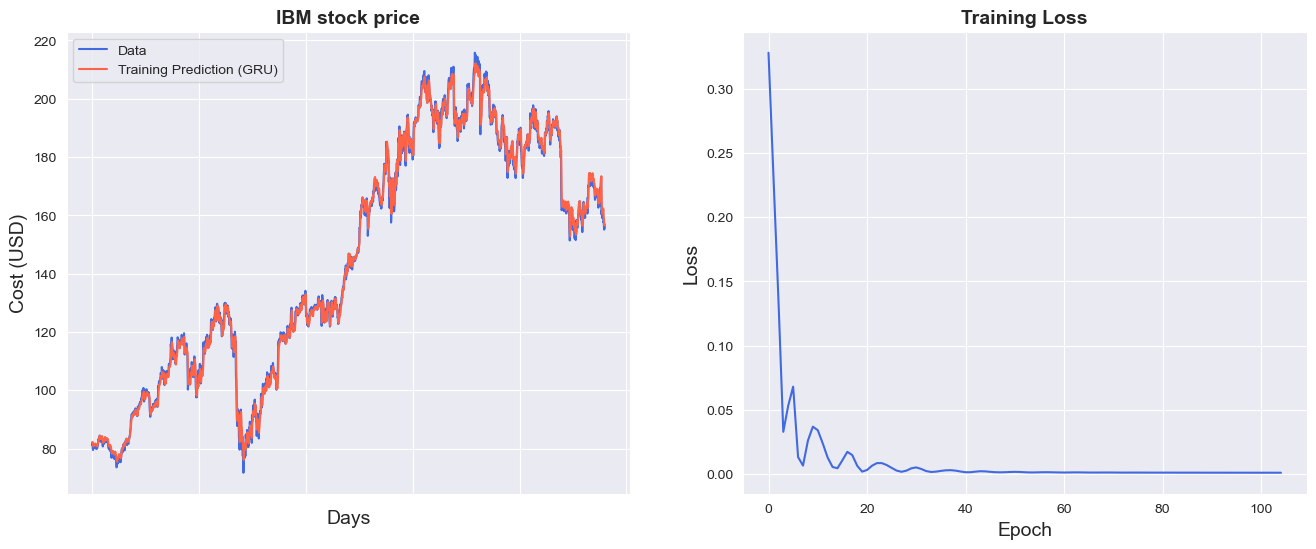

In [99]:
sns.set_style("darkgrid")    

fig = plt.figure()
fig.subplots_adjust(hspace=0.2, wspace=0.2)

plt.subplot(1, 2, 1)
ax = sns.lineplot(x = original.index, y = original[0], label="Data", color='royalblue')
ax = sns.lineplot(x = predict.index, y = predict[0], label="Training Prediction (GRU)", color='tomato')
ax.set_title('IBM stock price', size = 14, fontweight='bold')
ax.set_xlabel("Days", size = 14)
ax.set_ylabel("Cost (USD)", size = 14)
ax.set_xticklabels('', size=10)


plt.subplot(1, 2, 2)
ax = sns.lineplot(data=hist, color='royalblue')
ax.set_xlabel("Epoch", size = 14)
ax.set_ylabel("Loss", size = 14)
ax.set_title("Training Loss", size = 14, fontweight='bold')
fig.set_figheight(6)
fig.set_figwidth(16)

In [100]:
# make predictions
y_test_pred = model(x_test)

# invert predictions
y_train_pred = scaler.inverse_transform(y_train_pred.detach().numpy())
y_train = scaler.inverse_transform(y_train_gru.detach().numpy())
y_test_pred = scaler.inverse_transform(y_test_pred.detach().numpy())
y_test = scaler.inverse_transform(y_test_gru.detach().numpy())

# calculate root mean squared error
trainScore = math.sqrt(mean_squared_error(y_train[:,0], y_train_pred[:,0]))
print('Train Score: %.2f RMSE' % (trainScore))
testScore = math.sqrt(mean_squared_error(y_test[:,0], y_test_pred[:,0]))
print('Test Score: %.2f RMSE' % (testScore))
gru.append(trainScore)
gru.append(testScore)
gru.append(training_time)

Train Score: 2.15 RMSE
Test Score: 2.05 RMSE


In [101]:
# shift train predictions for plotting
trainPredictPlot = np.empty_like(price_ibm)
trainPredictPlot[:, :] = np.nan
trainPredictPlot[lookback:len(y_train_pred)+lookback, :] = y_train_pred

# shift test predictions for plotting
testPredictPlot = np.empty_like(price_ibm)
testPredictPlot[:, :] = np.nan
testPredictPlot[len(y_train_pred)+lookback-1:len(price_ibm)-1, :] = y_test_pred

original = scaler.inverse_transform(price_ibm['Close'].values.reshape(-1,1))

predictions = np.append(trainPredictPlot, testPredictPlot, axis=1)
predictions = np.append(predictions, original, axis=1)
result = pd.DataFrame(predictions)

In [103]:
fig = go.Figure()
fig.add_trace(go.Scatter(go.Scatter(x=result.index, 
                                    y=result[0],
                                    mode='lines',
                                    name='Train prediction')))
fig.add_trace(go.Scatter(x=result.index, 
                         y=result[1],
                         mode='lines',
                         name='Test prediction'))
fig.add_trace(go.Scatter(go.Scatter(x=result.index, 
                                    y=result[2],
                                    mode='lines',
                                    name='Actual Value')))
fig.update_layout(xaxis=dict(showline=True,
                             showgrid=True,
                             showticklabels=False,
                             linecolor='white',
                             linewidth=2),
                  yaxis=dict(title_text='Close (USD)',
                             titlefont=dict(family='Rockwell',
                                            size=12,
                                            color='white'),
                             showline=True,
                             showgrid=True,
                             showticklabels=True
                             ,linecolor='white',
                             linewidth=2,
                             ticks='outside',
                             tickfont=dict(family='Rockwell',
                                           size=12,
                                           color='white')),
                  showlegend=True,
                  template = 'plotly_dark')

annotations = []
annotations.append(dict(xref='paper', 
                        yref='paper',
                        x=0.0, 
                        y=1.05,
                        xanchor='left', 
                        yanchor='bottom',
                        text='IBM Stock Prediction',
                        font=dict(family='Rockwell',
                                  size=26,
                                  color='white'),
                        showarrow=False))
fig.update_layout(annotations=annotations)

fig.show()